# Hauptexperiment III: Verlustmuster einzelner Ausgangsfakten

**Kapitel 4.4 · explorative Forschungsfrage F4 · aktuell_20260930**

Wann wird derselbe Ausgangsfakt erstmals nicht als *Retained* bewertet? Bleibt diese
Bewertung bestehen, oder wechselt das QA-Label später zurück? Welche Unterschiede
zeigen die tatsächlich erfassten Entitätstypen?

Dieses Notebook verfolgt **2.000 Ausgangsfakten aus 100 Artikeln** über sechs Verfahren
und vier Zielstufen. Das ergibt **12.000 Faktenlaufbahnen mit 48.000 QA-Positionen**.
Es ergänzt Kapitel 4.2 durch Laufbahnen und Entitätstypen. Zwei Hauptabbildungen,
prüfbare Übergangstabellen, konkrete Rückkehrbelege und ein kurzer Kapiteltext werden
beim Ausführen neu erzeugt. Keine Modellaufrufe oder API-Zugänge sind erforderlich.

## Eingaben, Ausführung und Grenzen

Eingaben: prüfsummengebundene historische Quellen aus `data/eingefrorene_quellen.zip`;
unverändertes Originalnotebook: `data/referenznotebooks.zip::hauptexperiment_03_verlustmuster.ipynb`.
Ausgaben: `LAUF/workspace/project/02_Auswertung/hauptexperiment_verlust_ergebnisse/aktuell_20260930/` und die unten im Code bezeichneten Grafikordner.
Lauf mit frischem Kernel: `python 05_analyze.py --only 05_verlustmuster`.
Abhängigkeiten werden vom Runner zuerst mit eigenen frischen Kerneln ausgeführt:
`03_qa_retention`.

Für Jupyter: Paket installieren, mit `python 05_analyze.py --prepare --only 05_verlustmuster --output results/runs/interaktiv`
die Quellen vorbereiten und `FAKTENRETENTION_WORK` auf dieses explizite `workspace` setzen.
Bei abhängigen Notebooks zuerst die genannten Analysen ausführen (siehe `notebooks/README.md`).
Keine Modelle und keine neuen Modellmetriken. Humanratings und Panelmodelle gelten ausschließlich für den historischen Bestand.
Statistische Verfahren, Seeds, Supportfilter und fehlende Werte behalten ihre jeweilige Originaldefinition.


In [1]:
# Explizite Parameter: Pfade aus der Laufkonfiguration, kein vorbereiteter Kernelzustand.
from faktenretention.notebook_context import open_context
context = open_context("05_verlustmuster")
WORK = context.work
CONTEXT_BASE = WORK / "project/02_Auswertung"
recompute_bootstrap = False  # Historische Regressionscaches sind verpflichtend.


## 1. Definitionen und Grenzen

**Identität:** Artikel-ID + kanonische Fakten-ID bezeichnen denselben Ausgangsfakt.
Eine Laufbahn ist Artikel × Fakten-ID × Verfahren, in der Reihenfolge **500 → 300 → 150 → 75**.
Die erste Stufe ist bereits eine Zusammenfassung: „erstmals bei 500“ bedeutet eine
Bewertung an dieser ersten beobachteten Stufe, keinen bekannten Verlustzeitpunkt im Original.

| Quelllabel | Bedeutung in dieser Auswertung |
|---|---|
| `retained` | Die automatisch extrahierte Antwort erfüllt den eingefrorenen Referenzabgleich. |
| `lost` | Auswertbare Antwort `NOT_FOUND`. |
| `reference_discordant` | Auswertbare, textbelegte Antwort, die den Referenzabgleich nicht erfüllt. |
| `technical_missing` | Technisch nicht auswertbares QA-Urteil; kein inhaltliches Verlustlabel. |

**Ein eigenes Quelllabel `Unsupported` liegt nicht vor.** Referenzabweichungen werden
mit ihrem tatsächlichen Namen berichtet, nicht als gesicherte unbelegte Information
oder Halluzination. In der zusammenfassenden Darstellung bedeutet **nicht Retained =
Lost oder reference_discordant**. Beide bleiben in den Detailtabellen getrennt.
Auch Lost ist ein automatisches Messurteil, kein unabhängig bestätigtes Verschwinden.

**Fehlwerte:** Liegt ein technischer Fehlwert vor dem ersten beobachteten Nicht-Retained-Label,
ist die erste Stufe nicht eindeutig bestimmbar. Das gilt auch bei ansonsten ausschließlich
Retained-Labels. Ein Fehlwert *nach* einer bereits eindeutig bestimmten ersten Stufe
ändert deren Zuordnung nicht, kann aber Aussagen zur anschließenden Persistenz verhindern.

**Version:** Ausschließlich aktuell_20260930: vier ursprüngliche Verfahren und die
ersetzten Plain-/Few-Shot-CoT-Ketten. Keine Poolung mit original_frozen. Leere
Generierungsausgaben bleiben als End-to-end-Fehler sichtbar: deren regelbasierte
NOT_FOUND-Positionen sind keine technischen QA-Fehlwerte und keine Modellantworten.
Eine gemeinsame Sensitivität ohne die betroffenen Artikel steht im Anhang.

**Entitätstypen:** Nur `entity_type` des Hauptexperiments. Core, Supporting und Peripheral
stammen aus einer getrennten Human-Prüfung und werden hier nicht zugeordnet.
Keine neu erfundenen Faktentypen, keine vorab postulierte Typenrangfolge.

**Unsicherheit:** Punktweise 95-%-Perzentilintervalle aus 10.000 Artikelbootstrap-Ziehungen
(Seed 32). Ein gezogener Artikel bringt sämtliche Fakten, Verfahren und Stufen mit.
Die Intervalle erfassen Artikelheterogenität bei fixierten automatischen Labels,
keine Unsicherheit des QA-Modells und keine Korrektur für Mehrfachvergleiche.

In [2]:
from pathlib import Path
import gzip, hashlib, importlib.util, importlib.metadata, json, platform, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown, HTML
BASE = next((p for p in [CONTEXT_BASE, CONTEXT_BASE/"Notebooks und Grafiken"]
             if (p/"hauptexperiment_qa_daten/source_manifest.json").is_file()), None)
if BASE is None: raise FileNotFoundError("Im Ordner mit hauptexperiment_qa_daten ausführen.")
VERSION = "aktuell_20260930"
DATA = BASE/"hauptexperiment_qa_daten"
SOURCE42 = BASE/"hauptexperiment_qa_ergebnisse"/VERSION
OUT = BASE/"hauptexperiment_verlust_ergebnisse"/VERSION
FIG = BASE/"hauptexperiment_verlust_grafiken"/VERSION
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
METHODS = ["lead_k", "plain", "zero_shot_cot", "few_shot_cot", "auto_cot", "automate_cot"]
LABELS = dict(zip(METHODS, ["Lead-k", "Plain", "Zero-Shot-CoT", "Few-Shot-CoT", "Auto-CoT", "Automate-CoT"]))
COLORS = dict(zip(METHODS, ["#777777", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]))
MARKERS = dict(zip(METHODS, ["o", "s", "^", "D", "v", "P"]))
STAGES = [500, 300, 150, 75]
SEED, B = 32, 10_000
KEY = ["article_id", "method", "stage_target_words", "canonical_fact_id"]
PATHKEY = ["article_id", "method", "canonical_fact_id"]
R, L, D, M = "retained", "lost", "reference_discordant", "technical_missing"
STATES = [R, L, D, M]; NON = {L, D}
STATE_NAMES = {R:"Retained", L:"Lost", D:"Referenzabweichend", M:"Technisch fehlend"}
FIRSTS = ["500", "300", "150", "75", "always_retained", "undetermined"]
FIRST_NAMES = {str(t): f"Erstmals bei {t} Wörtern" for t in STAGES}
FIRST_NAMES.update(always_retained="Bis 75 durchgehend Retained", undetermined="Nicht eindeutig bestimmbar")
pd.set_option("display.max_columns", 24); pd.set_option("display.max_rows", 35)
plt.rcParams.update({"figure.dpi":110, "savefig.dpi":220, "font.size":10,
                     "axes.spines.top":False, "axes.spines.right":False})
def read(p): return pd.read_csv(p, keep_default_na=False, low_memory=False)
def fmt(v, d=1): return f"{v:.{d}f}".replace(".", ",")
def export(df, name): df.to_csv(OUT/f"{name}.csv", index=False)
def savefig(fig, name):
    for ext in ["png", "svg", "pdf"]: fig.savefig(FIG/f"{name}.{ext}", bbox_inches="tight")
    plt.show(); plt.close(fig)
def as_bool(s):
    assert s.astype(str).str.lower().isin(["true", "false"]).all()
    return s.astype(str).str.lower().eq("true")
software = {p:importlib.metadata.version(p) for p in ["numpy","pandas","matplotlib","nbformat","nbclient"]}

## 2. Quellen, Schlüssel und Reproduktion der Labels

Die lokalen Snapshots werden per SHA-256 geprüft. Die QA-Labels werden aus den
Rohantworten und dem eingefrorenen Scorer neu berechnet und positionsgenau mit Kapitel 4.2
verglichen. Fehlende Zeilen, doppelte Schlüssel und veränderte Faktenzuordnungen führen
zum Abbruch. Technische Fehler in vorhandenen Positionen werden separat ausgewertet.

In [3]:
manifest = json.loads((DATA/"source_manifest.json").read_text())
source_hashes = []
for e in manifest["files"]:
    if not e["file"].startswith((VERSION+"/", "shared/", "code/")): continue
    p = DATA/e["file"]
    digest = hashlib.sha256(p.read_bytes()).hexdigest()
    assert digest == e["sha256"], p
    if p.suffix == ".gz": assert hashlib.sha256(gzip.decompress(p.read_bytes())).hexdigest() == e["original_sha256"], p
    source_hashes.append({"file":str(p.relative_to(BASE)), "sha256":digest, "role":"frozen_input"})
for name in ["qa_labels_reproduziert.csv.gz", "execution_manifest.json"]:
    p = SOURCE42/name
    source_hashes.append({"file":str(p.relative_to(BASE)), "sha256":hashlib.sha256(p.read_bytes()).hexdigest(), "role":"chapter_4_2_crosscheck"})
assert json.loads((SOURCE42/"execution_manifest.json").read_text())["version"] == VERSION
merge = json.loads((DATA/VERSION/"provenienz/result_merge_manifest.json").read_text())
assert merge["retained_historical_rows"] == 400
assert merge["replaced_plain_rows"] == merge["replaced_few_shot_rows"] == 100
assert merge["historical_plain_or_few_shot_rows_in_new_table"] == 0
facts = read(DATA/"shared/canonical_facts.csv.gz")
summaries = read(DATA/VERSION/"summaries.csv.gz")
raw = read(DATA/VERSION/"answers.csv.gz").rename(columns={"summary_prompt_variant":"method"})
labels42 = read(SOURCE42/"qa_labels_reproduziert.csv.gz")
IDS = sorted(facts.article_id.unique().tolist())
assert len(IDS) == 100 and len(facts) == 2000
assert facts.canonical_fact_id.is_unique and not facts.duplicated(["article_id","canonical_fact_id"]).any()
assert facts.groupby("article_id").size().eq(20).all() and facts.entity_type.ne("").all()
assert len(summaries) == 600 and not summaries.duplicated(["article_id","method"]).any()
assert set(summaries[["article_id","method"]].itertuples(index=False,name=None)) == {(a,m) for a in IDS for m in METHODS}
phase = {m:"plain_fewshot_rerun_20260930" if m in ["plain","few_shot_cot"] else "final_100_frozen_temperature_0" for m in METHODS}
assert summaries.collection_phase.eq(summaries.method.map(phase)).all()
assert len(raw) == len(labels42) == 48000 and not raw.duplicated(KEY).any() and not labels42.duplicated(KEY).any()
expected = {(a,m,t,f) for a,f in facts[["article_id","canonical_fact_id"]].itertuples(index=False,name=None) for m in METHODS for t in STAGES}
assert set(raw[KEY].itertuples(index=False,name=None)) == expected
assert set(labels42[KEY].itertuples(index=False,name=None)) == expected
qa = raw.merge(facts[["article_id","canonical_fact_id","entity_type","fact","question","reference_answer","source_evidence"]],
               on=["article_id","canonical_fact_id"], validate="many_to_one", suffixes=("","_canonical"))
for col in ["entity_type","question","reference_answer"]:
    assert qa[col].eq(qa[col+"_canonical"]).all(), col
    qa = qa.drop(columns=col+"_canonical")
summary_long = pd.concat([summaries[["article_id","method",f"summary_{t}"]].rename(columns={f"summary_{t}":"summary"}).assign(stage_target_words=t) for t in STAGES], ignore_index=True)
qa = qa.merge(summary_long, on=["article_id","method","stage_target_words"], validate="many_to_one")
from faktenretention import scoring as scorer
qa["technical_missing"] = qa.error.ne("")
qa["analysis_eligible"] = ~qa.technical_missing
qa["grounded"] = [scorer.support_is_grounded(s,a,e) for s,a,e in zip(qa.summary,qa.answer,qa.support)]
assert qa.loc[qa.analysis_eligible,"grounded"].all()
assert qa.loc[qa.analysis_eligible,"answer"].str.strip().ne("").all()
qa["is_retained"] = [scorer.retained(ref,a) if ok else False for ref,a,ok in zip(qa.reference_answer,qa.answer,qa.analysis_eligible)]
qa["label"] = np.select([qa.technical_missing,qa.is_retained,qa.answer.str.upper().eq("NOT_FOUND")],[M,R,L],default=D)
check = qa.merge(labels42[KEY+["label","answer","support","technical_missing","analysis_eligible","grounded","empty_output","chain_failure","answer_origin"]],on=KEY,validate="one_to_one",suffixes=("","_42"))
for col in ["label","answer","support"]: assert check[col].eq(check[col+"_42"]).all(), col
for col in ["technical_missing","analysis_eligible","grounded"]: assert check[col].eq(as_bool(check[col+"_42"])).all(), col
qa = qa.merge(labels42[KEY+["empty_output","chain_failure","answer_origin"]],on=KEY,validate="one_to_one")
for col in ["empty_output","chain_failure"]: qa[col] = as_bool(qa[col])
assert qa.empty_output.eq(qa.summary.str.strip().eq("")).all()
assert qa.loc[qa.empty_output,"answer"].eq("NOT_FOUND").all()
assert qa.answer_origin.eq(np.where(qa.empty_output,"empty_summary_rule","qa_model")).all()
generation_flags = summary_long.copy()
generation_flags["stage_order"] = generation_flags.stage_target_words.map(dict(zip(STAGES,range(4))))
generation_flags = generation_flags.sort_values(["article_id","method","stage_order"])
generation_flags["empty_output"] = generation_flags.summary.str.strip().eq("")
generation_flags["derived_chain_failure"] = generation_flags.groupby(["article_id","method"]).empty_output.cummax()
failure_check = qa.merge(generation_flags[["article_id","method","stage_target_words","derived_chain_failure"]],
                         on=["article_id","method","stage_target_words"],validate="many_to_one")
assert failure_check.chain_failure.eq(failure_check.derived_chain_failure).all()
export(generation_flags[["article_id","method","stage_target_words","empty_output","derived_chain_failure"]],"generierungsfehler_positionen")
failed_ids = sorted(qa.loc[qa.chain_failure,"article_id"].unique().tolist())
status = qa.groupby(["method","stage_target_words","label"]).size().unstack(fill_value=0).reindex(columns=STATES,fill_value=0).reset_index()
status["n_expected"] = status[STATES].sum(axis=1)
assert status.n_expected.eq(2000).all()
export(status,"qa_status_getrennte_labels"); export(pd.DataFrame(source_hashes),"quellen_sha256")
qa[KEY+["entity_type","label","technical_missing","empty_output","chain_failure","answer_origin"]].to_csv(OUT/"qa_positionen.csv.gz",index=False)
display(status)
display(Markdown(f"**48.000/48.000 Labels positionsgenau reproduziert.** {int(qa.technical_missing.sum())} technische Fehlwerte; "
                 f"{int(qa.empty_output.sum())} regelbasierte NOT_FOUND-Positionen bei leeren Ausgaben; betroffene Artikel: {failed_ids}."))

label,method,stage_target_words,retained,lost,reference_discordant,technical_missing,n_expected
0,auto_cot,75,781,983,234,2,2000
1,auto_cot,150,1153,565,269,13,2000
2,auto_cot,300,1356,382,251,11,2000
3,auto_cot,500,1419,329,240,12,2000
4,automate_cot,75,738,1033,224,5,2000
5,automate_cot,150,1074,662,255,9,2000
6,automate_cot,300,1371,374,239,16,2000
7,automate_cot,500,1460,312,217,11,2000
8,few_shot_cot,75,688,1078,226,8,2000
9,few_shot_cot,150,1008,714,263,15,2000


**48.000/48.000 Labels positionsgenau reproduziert.** 196 technische Fehlwerte; 40 regelbasierte NOT_FOUND-Positionen bei leeren Ausgaben; betroffene Artikel: [40, 91].

## 3. Faktenlaufbahnen und Artikelbootstrap

Es wird keine neue Fakt-ID je Zusammenfassung gebildet. Jede Zeile der folgenden
Tabelle enthält die vier Labels desselben Ausgangsfakts unter demselben Verfahren.
Für alle Intervalle werden dieselben Artikelziehungen verwendet.

In [4]:
paths = qa.pivot(index=PATHKEY, columns="stage_target_words", values="label").reindex(columns=STAGES).reset_index()
assert len(paths) == 12000 and paths[STAGES].notna().all().all()
assert paths.groupby("method").size().eq(2000).all()
paths = paths.merge(facts[["article_id","canonical_fact_id","entity_type","fact"]],on=["article_id","canonical_fact_id"],validate="many_to_one")

def classify(seq):
    first_index = next((i for i,s in enumerate(seq) if s in NON), None)
    if first_index is None:
        first = "undetermined" if M in seq else "always_retained"
    else:
        first = "undetermined" if M in seq[:first_index] else str(STAGES[first_index])
    # Even an ambiguous first stage can have an observed N→...→R pattern.
    observed_return = first_index is not None and R in seq[first_index+1:]
    if first == "undetermined": persistence = "first_stage_undetermined"
    elif first == "always_retained": persistence = "always_retained"
    elif first_index == 3: persistence = "first_at_final_stage"
    elif observed_return: persistence = "observed_return"
    elif M in seq[first_index+1:]: persistence = "persistence_undetermined"
    else: persistence = "all_later_non_retained"
    return first, (seq[first_index] if first_index is not None else ""), persistence, observed_return

# Boundary checks: missing before / after the first negative and right-censoring at 75.
assert classify([R,M,L,R])[:3] == ("undetermined",L,"first_stage_undetermined")
assert classify([R,L,M,L])[:3] == ("300",L,"persistence_undetermined")
assert classify([R,R,R,L])[:3] == ("75",L,"first_at_final_stage")
assert classify([R,R,M,R])[0] == "undetermined"
assert classify([L,R,L,L])[2] == "observed_return"
assert classify([R,R,R,R])[0] == "always_retained"
result = [classify(seq) for seq in paths[STAGES].itertuples(index=False,name=None)]
paths[["first_category","first_observed_nonretained_label","persistence","observed_return_any"]] = pd.DataFrame(result,index=paths.index)
paths["n_missing"] = paths[STAGES].eq(M).sum(axis=1)
paths["label_sequence"] = paths[STAGES].agg(" → ".join,axis=1)
export(paths,"faktenlaufbahnen")

rng = np.random.default_rng(SEED)
draws = rng.integers(0,len(IDS),size=(B,len(IDS)))
weights = np.zeros((B,len(IDS)),dtype=np.int16)
np.add.at(weights,(np.repeat(np.arange(B),len(IDS)),draws.ravel()),1)
assert weights.sum(axis=1).tolist() == [len(IDS)]*B

def estimate_ratio(frame, numerator, denominator):
    """Ratio of pooled counts; articles with no group facts contribute zero counts."""
    counts = frame.groupby("article_id")[[numerator,denominator]].sum().reindex(IDS,fill_value=0).to_numpy(dtype=float)
    k,v = counts.sum(axis=0)
    boot = weights @ counts
    ratios = np.divide(boot[:,0],boot[:,1],out=np.full(B,np.nan),where=boot[:,1]>0)
    ci = np.nanquantile(ratios,[.025,.975]) if np.isfinite(ratios).any() else [np.nan,np.nan]
    return {"estimate":k/v if v else np.nan,"ci_low":float(ci[0]),"ci_high":float(ci[1]),
            "n_numerator":int(k),"n_denominator":int(v),"n_articles_denominator":int((counts[:,1]>0).sum()),
            "bootstrap_draws_zero_denominator":int(np.isnan(ratios).sum())}
first_rows = []
for method in METHODS:
    sub = paths[paths.method.eq(method)].copy(); sub["den"] = 1
    for cat in FIRSTS:
        sub["num"] = sub.first_category.eq(cat).astype(int)
        first_rows.append({"method":method,"category":cat,"category_name":FIRST_NAMES[cat],**estimate_ratio(sub,"num","den")})
firsts = pd.DataFrame(first_rows)
assert firsts.groupby("method").n_numerator.sum().eq(2000).all()
export(firsts,"erste_nicht_retained_stufe_95ci")
export(paths.groupby(["method","first_category","first_observed_nonretained_label"]).size().rename("n_paths").reset_index(),"erste_stufe_quelllabel_getrennt")
display(firsts.pivot(index="method",columns="category",values="n_numerator").reindex(index=METHODS,columns=FIRSTS).rename(index=LABELS,columns=FIRST_NAMES))

category,Erstmals bei 500 Wörtern,Erstmals bei 300 Wörtern,Erstmals bei 150 Wörtern,Erstmals bei 75 Wörtern,Bis 75 durchgehend Retained,Nicht eindeutig bestimmbar
method,,,,,,
Lead-k,487,532,388,254,332,7
Plain,898,122,101,229,634,16
Zero-Shot-CoT,560,103,295,489,544,9
Few-Shot-CoT,710,82,222,323,638,25
Auto-CoT,569,88,228,381,717,17
Automate-CoT,529,114,315,329,691,22


## 4.4.1 Verlust entlang der Kompressionskette

### Hauptabbildung 1: erste Nicht-Retained-Bewertung

Alle 2.000 Laufbahnen je Verfahren bilden den Nenner. Grau schraffierte Laufbahnen
lassen die erste Stufe wegen technischer Fehlwerte offen. Frühere Nicht-Retained-Labels
bleiben einer Stufe zugeordnet, auch wenn später wieder Retained erscheint.
Die Grafik beschreibt die **erste Nicht-Retained-Bewertung**, keine irreversible
Textverlustkurve. Die zugehörigen Artikelbootstrap-Intervalle stehen in der Tabelle.

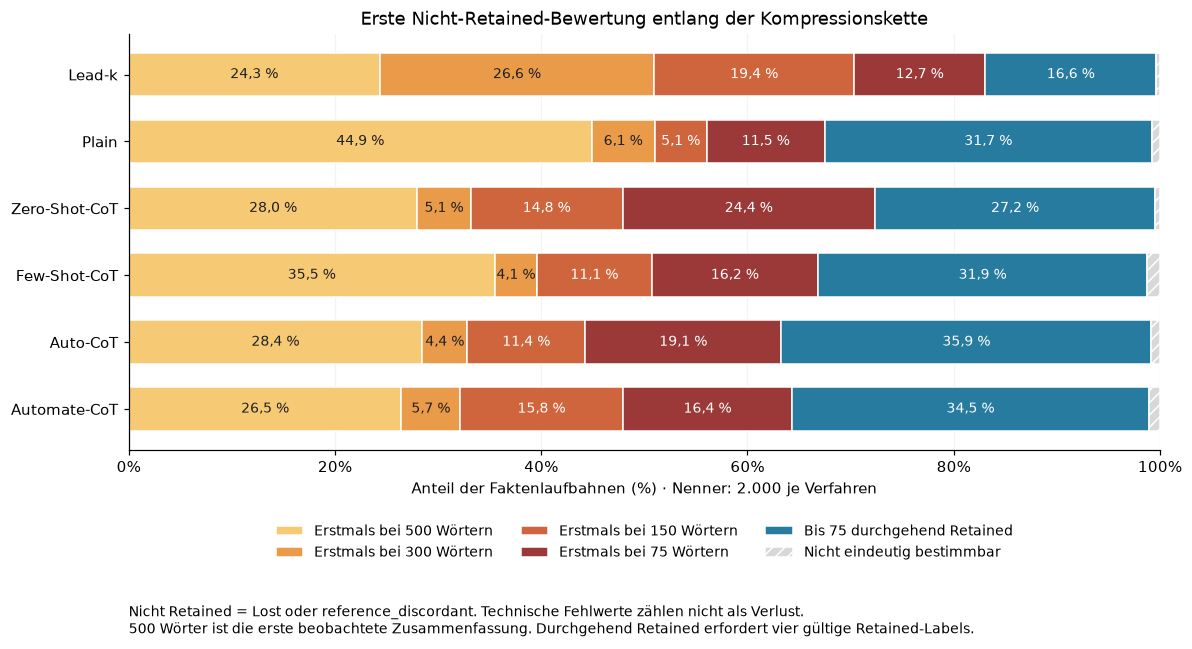

In [5]:
barcolors = ["#F6C975","#E99B49","#CE653C","#9B3838","#267B9E","#D8D8D8"]
fig, ax = plt.subplots(figsize=(12.5,6.3))
left = np.zeros(len(METHODS))
for cat,color in zip(FIRSTS,barcolors):
    vals = firsts[firsts.category.eq(cat)].set_index("method").loc[METHODS,"estimate"].to_numpy()*100
    bars = ax.barh(np.arange(6),vals,left=left,color=color,edgecolor="white",height=.65,
                   label=FIRST_NAMES[cat],hatch="///" if cat=="undetermined" else None)
    counts = firsts[firsts.category.eq(cat)].set_index("method").loc[METHODS,"n_numerator"]
    for i,(v,n) in enumerate(zip(vals,counts)):
        if v>=3: ax.text(left[i]+v/2,i,f"{fmt(v)} %",ha="center",va="center",fontsize=9,
                        color="white" if cat in ["150","75","always_retained"] else "#202020")
    left += vals
ax.set(yticks=np.arange(6),yticklabels=[LABELS[m] for m in METHODS],xlim=(0,100),
       xlabel="Anteil der Faktenlaufbahnen (%) · Nenner: 2.000 je Verfahren",
       title="Erste Nicht-Retained-Bewertung entlang der Kompressionskette")
ax.invert_yaxis(); ax.xaxis.set_major_formatter(PercentFormatter(100)); ax.grid(axis="x",alpha=.15); ax.set_axisbelow(True)
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.15),ncol=3,frameon=False,fontsize=9)
fig.subplots_adjust(bottom=.28,left=.15)
fig.text(.15,.015,"Nicht Retained = Lost oder reference_discordant. Technische Fehlwerte zählen nicht als Verlust.\n"
         "500 Wörter ist die erste beobachtete Zusammenfassung. Durchgehend Retained erfordert vier gültige Retained-Labels.",fontsize=9)
savefig(fig,"01_erste_nicht_retained_stufe")

### Was geschieht nach der ersten Nicht-Retained-Bewertung?

Die Persistenzquote bezieht sich auf Laufbahnen mit **eindeutiger erster Stufe vor 75**.
„Danach durchgehend nicht Retained“ verlangt gültige Nicht-Retained-Labels auf allen
folgenden Stufen. „Beobachtete Rückkehr“ verlangt mindestens ein späteres Retained-Label;
zwischenliegende Fehlwerte schließen diese Beobachtung nicht aus. Ohne Rückkehr und
mit späteren Fehlwerten bleibt die Persistenz offen. Eine erste Bewertung bei 75 hat
keine Folgestufe und wird separat ausgewiesen.

In [6]:
persistence_rows = []
for method in METHODS:
    sub = paths[paths.method.eq(method)].copy()
    risk = sub.first_category.isin(["500","300","150"])
    sub["den"] = risk.astype(int)
    for outcome in ["all_later_non_retained","observed_return","persistence_undetermined"]:
        sub["num"] = (risk & sub.persistence.eq(outcome)).astype(int)
        persistence_rows.append({"method":method,"outcome":outcome,**estimate_ratio(sub,"num","den")})
persistence = pd.DataFrame(persistence_rows)
assert persistence.groupby("method").n_numerator.sum().equals(persistence.groupby("method").n_denominator.first())
export(persistence,"persistenz_nach_erster_stufe_95ci")
path_overview = paths.groupby("method").agg(n_paths=("canonical_fact_id","size"),
    n_paths_with_missing=("n_missing",lambda s:int(s.gt(0).sum())),
    n_any_observed_return=("observed_return_any","sum"))
path_overview["n_first_at_75"] = paths[paths.first_category.eq("75")].groupby("method").size().reindex(path_overview.index,fill_value=0)
path_overview["n_first_undetermined"] = paths[paths.first_category.eq("undetermined")].groupby("method").size().reindex(path_overview.index,fill_value=0)
export(path_overview.reset_index(),"laufbahnen_ueberblick")
display(persistence[["method","outcome","n_numerator","n_denominator","estimate","ci_low","ci_high"]].round(4))
display(path_overview.rename(index=LABELS))

,method,outcome,n_numerator,n_denominator,estimate,ci_low,ci_high
0,lead_k,all_later_non_retained,1384,1407,0.9837,0.9768,0.9899
1,lead_k,observed_return,21,1407,0.0149,0.0092,0.0212
2,lead_k,persistence_undetermined,2,1407,0.0014,0.0000,0.0036
3,plain,all_later_non_retained,1064,1121,0.9492,0.9365,0.9613
4,plain,observed_return,53,1121,0.0473,0.0353,0.0602
5,plain,persistence_undetermined,4,1121,0.0036,0.0009,0.0073
6,zero_shot_cot,all_later_non_retained,882,958,0.9207,0.9005,0.9397
7,zero_shot_cot,observed_return,72,958,0.0752,0.0563,0.0948
8,zero_shot_cot,persistence_undetermined,4,958,0.0042,0.0010,0.0085
9,few_shot_cot,all_later_non_retained,919,1014,0.9063,0.8871,0.9240


,n_paths,n_paths_with_missing,n_any_observed_return,n_first_at_75,n_first_undetermined
method,,,,,
Auto-CoT,2000,23,92,381,17
Automate-CoT,2000,27,81,329,22
Few-Shot-CoT,2000,37,86,323,25
Lead-k,2000,9,22,254,7
Plain,2000,20,53,229,16
Zero-Shot-CoT,2000,13,72,489,9


### Drei Übergänge: Labelwechsel und klare Nenner

Pro Stufenpaar sind 2.000 Laufbahnen je Verfahren vorgesehen. Die **Paarquote** verwendet
nur Laufbahnen mit zwei gültigen Endpunkten. Daneben wird die **bedingte Quote** angegeben:
Retained → nicht Retained unter den gültigen Paaren mit Retained-Ausgangslabel;
nicht Retained → Retained unter denen mit nicht-Retained-Ausgangslabel.
Damit sind sowohl der Umfang aller Wechsel als auch die Wechselwahrscheinlichkeit
unter den jeweils betroffenen Ausgangslabels sichtbar. Fehlwerte an einem der beiden
Endpunkte werden ausgeschlossen und gezählt. Rückkehr bezeichnet hier einen QA-Labelwechsel.

In [7]:
transition_rows, matrix_rows, pair_frames = [], [], []
for method in METHODS:
    sub = paths[paths.method.eq(method)]
    for before,after in zip(STAGES[:-1],STAGES[1:]):
        pair = sub[["article_id","canonical_fact_id",before,after]].rename(columns={before:"from_label",after:"to_label"}).copy()
        pair["method"] = method; pair["from_stage"] = before; pair["to_stage"] = after
        pair["valid_pair"] = ~pair.from_label.eq(M) & ~pair.to_label.eq(M)
        pair["r_start"] = pair.valid_pair & pair.from_label.eq(R)
        pair["n_start"] = pair.valid_pair & pair.from_label.isin(NON)
        pair["r_to_n"] = pair.valid_pair & pair.from_label.eq(R) & pair.to_label.isin(NON)
        pair["n_to_r"] = pair.valid_pair & pair.from_label.isin(NON) & pair.to_label.eq(R)
        pair_frames.append(pair)
        rec = {"method":method,"transition":f"{before}→{after}","from_stage":before,"to_stage":after,
               "n_expected":len(pair),"n_valid_pairs":int(pair.valid_pair.sum()),
               "n_missing_either":int((~pair.valid_pair).sum()),
               "n_missing_before":int(pair.from_label.eq(M).sum()),"n_missing_after":int(pair.to_label.eq(M).sum())}
        for num,den,name in [("r_to_n","valid_pair","r_to_n_pair"),("n_to_r","valid_pair","n_to_r_pair"),
                             ("r_to_n","r_start","r_to_n_conditional"),("n_to_r","n_start","n_to_r_conditional")]:
            rec.update({name+"_"+k:v for k,v in estimate_ratio(pair,num,den).items()})
        transition_rows.append(rec)
        matrix = pd.crosstab(pair.from_label,pair.to_label).reindex(index=STATES,columns=STATES,fill_value=0)
        assert matrix.to_numpy().sum()==2000
        for a in STATES:
            for b in STATES:
                count = int(matrix.loc[a,b]); row_total = int(matrix.loc[a].sum())
                matrix_rows.append({"method":method,"transition":f"{before}→{after}","from_label":a,"to_label":b,
                                    "n":count,"row_denominator_including_missing":row_total,
                                    "row_fraction_including_missing":count/row_total if row_total else np.nan})
transitions = pd.DataFrame(transition_rows); matrices = pd.DataFrame(matrix_rows)
pairs = pd.concat(pair_frames,ignore_index=True)
assert len(transitions)==18 and len(matrices)==288 and len(pairs)==36000
assert (transitions.n_valid_pairs+transitions.n_missing_either).eq(2000).all()
export(transitions,"labeluebergaenge_nenner_95ci"); export(matrices,"labeluebergaenge_4x4_absolut")
export(pairs[pairs.r_to_n|pairs.n_to_r],"labelwechsel_einzelfaelle")
transition_display = transitions[["method","transition","n_valid_pairs","n_missing_either"]].copy()
for name,label in [("r_to_n_pair","R → N, Paarquote"),("n_to_r_pair","N → R, Paarquote"),
                   ("r_to_n_conditional","R → N, bedingt"),("n_to_r_conditional","N → R, bedingt")]:
    transition_display[label] = [f"{int(r[name+'_n_numerator'])}/{int(r[name+'_n_denominator'])} ({fmt(100*r[name+'_estimate'])} %)" for _,r in transitions.iterrows()]
transition_display.method = transition_display.method.map(LABELS)
display(transition_display)

,method,transition,n_valid_pairs,n_missing_either,"R → N, Paarquote","N → R, Paarquote","R → N, bedingt","N → R, bedingt"
0,Lead-k,500→300,1994,6,"532/1994 (26,7 %)","10/1994 (0,5 %)","532/1507 (35,3 %)","10/487 (2,1 %)"
1,Lead-k,300→150,1994,6,"393/1994 (19,7 %)","9/1994 (0,5 %)","393/985 (39,9 %)","9/1009 (0,9 %)"
2,Lead-k,150→75,1996,4,"261/1996 (13,1 %)","4/1996 (0,2 %)","261/603 (43,3 %)","4/1393 (0,3 %)"
3,Plain,500→300,1986,14,"122/1986 (6,1 %)","26/1986 (1,3 %)","122/1089 (11,2 %)","26/897 (2,9 %)"
4,Plain,300→150,1984,16,"107/1984 (5,4 %)","12/1984 (0,6 %)","107/992 (10,8 %)","12/992 (1,2 %)"
5,Plain,150→75,1987,13,"241/1987 (12,1 %)","16/1987 (0,8 %)","241/896 (26,9 %)","16/1091 (1,5 %)"
6,Zero-Shot-CoT,500→300,1990,10,"103/1990 (5,2 %)","22/1990 (1,1 %)","103/1432 (7,2 %)","22/558 (3,9 %)"
7,Zero-Shot-CoT,300→150,1990,10,"307/1990 (15,4 %)","27/1990 (1,4 %)","307/1351 (22,7 %)","27/639 (4,2 %)"
8,Zero-Shot-CoT,150→75,1994,6,"518/1994 (26,0 %)","25/1994 (1,3 %)","518/1071 (48,4 %)","25/923 (2,7 %)"
9,Few-Shot-CoT,500→300,1980,20,"82/1980 (4,1 %)","23/1980 (1,2 %)","82/1271 (6,5 %)","23/709 (3,2 %)"


## 4.4.2 Unterschiede nach Entitätstyp

**Kennzahl:** Anzahl Retained / Anzahl gültiger QA-Urteile pro Typ × Verfahren × Stufe.
Dies ist ein **faktengewichteter Anteil**. Artikel mit mehr Fakten eines Typs liefern
mehr QA-Positionen; Kapitel 4.2 verwendete dagegen gleichgewichtete Artikelmittel.
Die Fallzahl eines Typs zählt die ursprünglichen Fakten einmal, nicht erneut pro
Verfahren oder Stufe. Die gültigen Nenner und technischen Fehlwerte werden zusätzlich
für jede Kurve exportiert.

**Kleine Gruppe:** transparente Darstellungsschwelle von weniger als 100 Ausgangsfakten
oder weniger als 30 Artikeln. Das ist eine deskriptive Kennzeichnung, keine statistische
Testgrenze. Gruppen werden nicht entfernt. Punktweise Artikelbootstrap-Intervalle
bewerten keine vorab festgelegte Typenrangfolge.

In [8]:
type_counts = facts.groupby("entity_type").agg(n_facts=("canonical_fact_id","size"),n_articles=("article_id","nunique")).sort_values("n_facts",ascending=False).reset_index()
type_counts["small_group"] = (type_counts.n_facts<100)|(type_counts.n_articles<30)
TYPES = type_counts.entity_type.tolist()
assert type_counts.n_facts.sum()==2000
export(type_counts,"entitaetstypen_fakten_und_artikel")
type_rows = []
for typ in TYPES:
    for method in METHODS:
        for stage in STAGES:
            sub = qa[qa.entity_type.eq(typ)&qa.method.eq(method)&qa.stage_target_words.eq(stage)].copy()
            sub["num"] = sub.label.eq(R).astype(int); sub["den"] = sub.analysis_eligible.astype(int)
            type_rows.append({"entity_type":typ,"method":method,"stage_target_words":stage,
                              "n_expected":len(sub),"n_missing":int(sub.technical_missing.sum()),
                              "n_lost":int(sub.label.eq(L).sum()),"n_reference_discordant":int(sub.label.eq(D).sum()),
                              "n_synthetic_not_found":int(sub.empty_output.sum()),**estimate_ratio(sub,"num","den")})
type_retention = pd.DataFrame(type_rows).merge(type_counts,on="entity_type",validate="many_to_one")
assert len(type_retention)==len(TYPES)*6*4
assert (type_retention.n_numerator+type_retention.n_lost+type_retention.n_reference_discordant).eq(type_retention.n_denominator).all()
assert (type_retention.n_denominator+type_retention.n_missing).eq(type_retention.n_expected).all()
export(type_retention,"retention_entitaetstyp_methoden_stufen_95ci")
display(type_counts)
display(Markdown("Die Fallzahlen stehen auch in jedem Paneltitel. Jede Fehlerbalkenspanne ist ein punktweises 95-%-Artikelbootstrap-Intervall; die dünnen Verbindungslinien verbinden nur die vier beobachteten Zielstufen."))

,entity_type,n_facts,n_articles,small_group
0,NUMBER,526,96,False
1,PERSON,420,97,False
2,LOCATION,255,93,False
3,DATE_TIME,216,90,False
4,OTHER,181,74,False
5,OBJECT,168,67,False
6,ORG,154,77,False
7,EVENT,80,53,True


Die Fallzahlen stehen auch in jedem Paneltitel. Jede Fehlerbalkenspanne ist ein punktweises 95-%-Artikelbootstrap-Intervall; die dünnen Verbindungslinien verbinden nur die vier beobachteten Zielstufen.

### Hauptabbildung 2: Retentionsverläufe nach Entitätstyp

Alle Panels verwenden dieselbe Skala von 0 bis 100 %. Die vier Positionen bilden die
Reihenfolge der Kompressionskette ab. Farben und Symbole bezeichnen die Verfahren.
Die leichte horizontale Versetzung trennt die Fehlerbalken; sie hat keine inhaltliche Bedeutung.
Alle acht Typen stehen in einem **4×2-Raster (vier Zeilen, zwei Spalten)**.

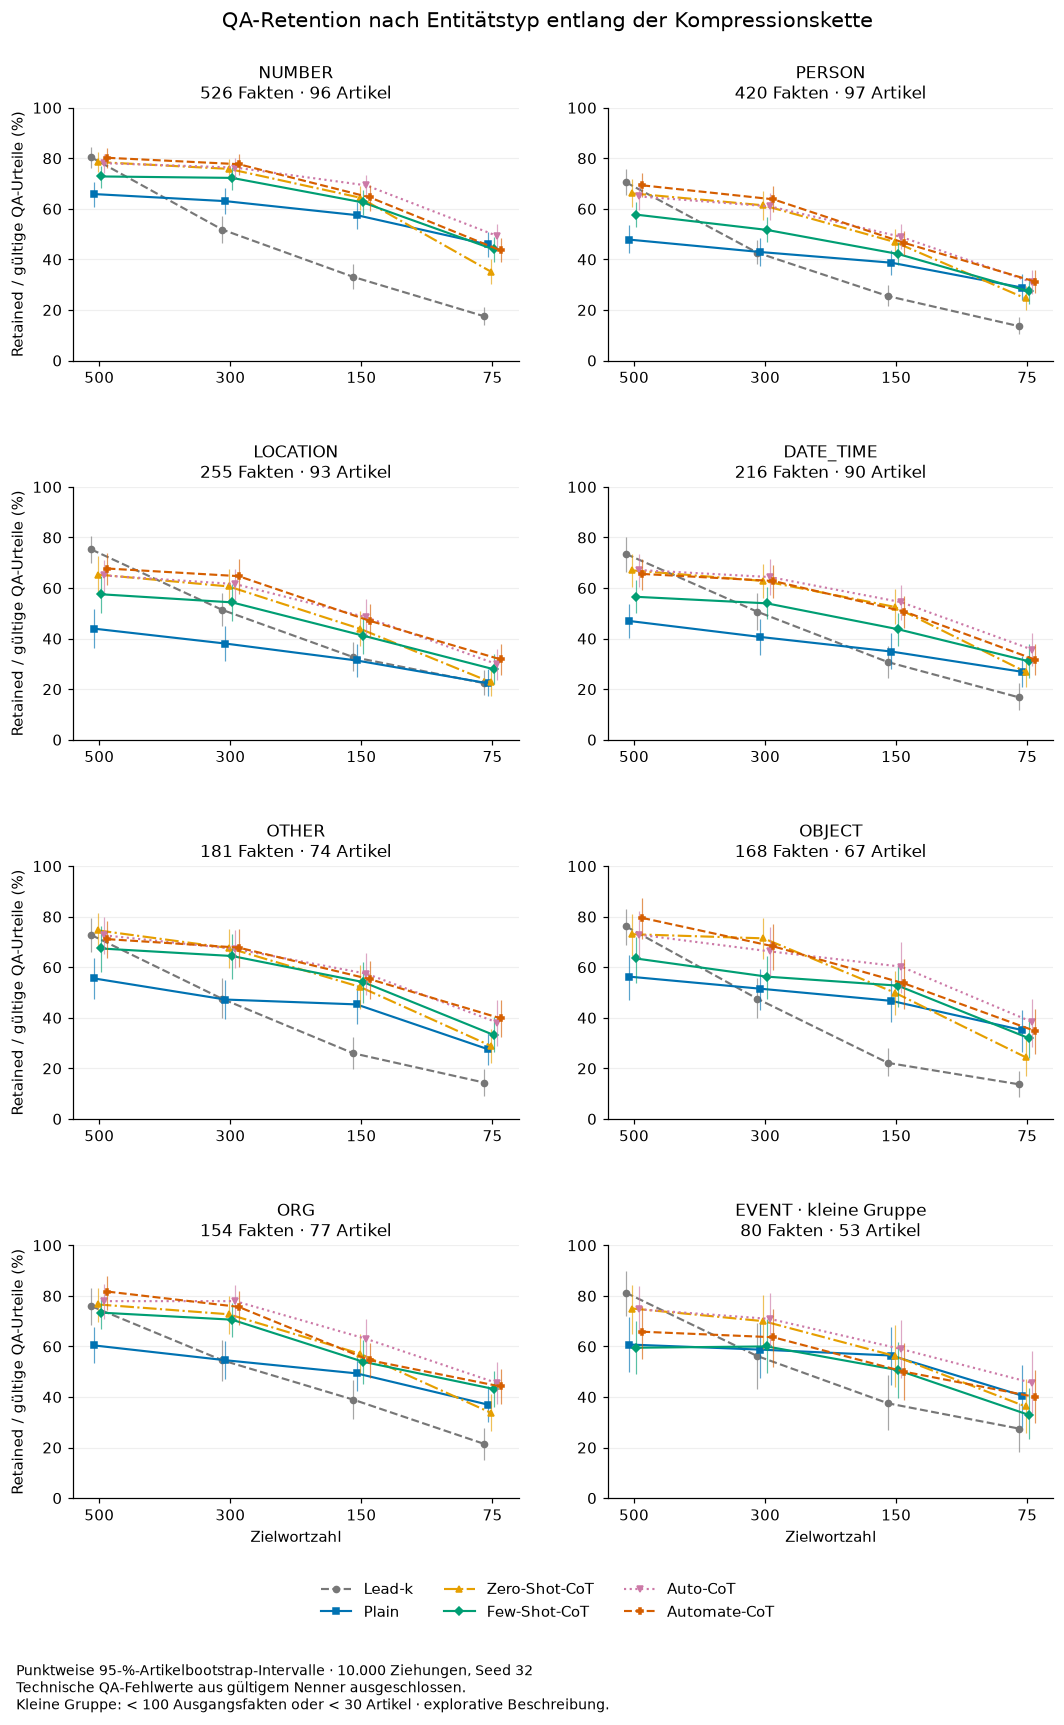

In [9]:
x = np.arange(4)
linestyles = ["--","-","-.","-",":","--"]
fig,axes = plt.subplots(4,2,figsize=(11.5,16),sharex=True,sharey=True)
for panel,(ax,typ) in enumerate(zip(axes.flat,TYPES)):
    counts = type_counts.set_index("entity_type").loc[typ]
    for i,method in enumerate(METHODS):
        sub = type_retention[type_retention.entity_type.eq(typ)&type_retention.method.eq(method)].set_index("stage_target_words").loc[STAGES]
        y = 100*sub.estimate.to_numpy(); offset = (i-2.5)*.025
        ax.vlines(x+offset,100*sub.ci_low,100*sub.ci_high,color=COLORS[method],alpha=.65,linewidth=.8)
        ax.plot(x+offset,y,color=COLORS[method],marker=MARKERS[method],linestyle=linestyles[i],
                linewidth=1.4,markersize=4,label=LABELS[method])
    small = " · kleine Gruppe" if counts.small_group else ""
    ax.set_title(f"{typ}{small}\n{int(counts.n_facts)} Fakten · {int(counts.n_articles)} Artikel",fontsize=11)
    ax.set(xticks=x,xticklabels=STAGES,yticks=np.arange(0,101,20),ylim=(0,100),xlim=(-.2,3.2))
    ax.grid(axis="y",alpha=.2); ax.tick_params(labelbottom=True,labelleft=True)
    if panel%2==0: ax.set_ylabel("Retained / gültige QA-Urteile (%)")
    if panel>=6: ax.set_xlabel("Zielwortzahl")
fig.subplots_adjust(top=.93,bottom=.14,hspace=.5,wspace=.2)
handles,labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc="upper center",bbox_to_anchor=(.5,.10),ncol=3,frameon=False)
fig.suptitle("QA-Retention nach Entitätstyp entlang der Kompressionskette",fontsize=14,y=.985)
fig.text(.08,.02,
         "Punktweise 95-%-Artikelbootstrap-Intervalle · 10.000 Ziehungen, Seed 32\n"
         "Technische QA-Fehlwerte aus gültigem Nenner ausgeschlossen.\n"
         "Kleine Gruppe: < 100 Ausgangsfakten oder < 30 Artikel · explorative Beschreibung.",fontsize=9)
savefig(fig,"02_retention_nach_entitaetstyp")

### Welche Entitätstypen verlieren zwischen zwei Stufen am häufigsten ein Retained-Label?

Für diesen Übergangsvergleich werden die fünf generativen Verfahren zusammengefasst;
Lead-k bleibt eine separate Baseline. Der **Verlustanteil** hat als Nenner nur gültige
Faktenläufe, die am Anfang des Übergangs Retained waren. Der Zähler ist die Zahl dieser
Faktenläufe, die am nächsten Schritt Lost oder referenzabweichend sind. Fehlende QA-
Urteile an einem der beiden Endpunkte werden ausgeschlossen. Rückwechsel in Gegenrichtung
werden separat gezählt und zusätzlich bei der Nettoänderung berücksichtigt.

Die Prozentintervalle beruhen auf einem Bootstrap ganzer Artikel; alle Fakten und
Verfahren eines gezogenen Artikels bleiben zusammen. Da jedes Ausgangsfakt unter fünf
Verfahren vorkommt, entsprechen die gepoolten Zähler Fakten-Verfahrens-Läufen, nicht
unabhängigen Ausgangsfakten. Rangfolgen sind explorativ; überlappende Intervalle erlauben
keine eindeutige Rangordnung.

### Welche Entitätstypen verlieren zwischen zwei Stufen am häufigsten ein Retained-Label?

Für diesen Übergangsvergleich werden die fünf generativen Verfahren zusammengefasst;
Lead-k bleibt eine separate Baseline. Der **Verlustanteil** hat als Nenner nur gültige
Faktenläufe, die am Anfang des Übergangs Retained waren. Der Zähler ist die Zahl dieser
Faktenläufe, die am nächsten Schritt Lost oder referenzabweichend sind. Fehlende QA-
Urteile an einem der beiden Endpunkte werden ausgeschlossen. Rückwechsel in Gegenrichtung
werden separat gezählt und zusätzlich bei der Nettoänderung berücksichtigt.

Die Prozentintervalle beruhen auf einem Bootstrap ganzer Artikel; alle Fakten und
Verfahren eines gezogenen Artikels bleiben zusammen. Da jedes Ausgangsfakt unter fünf
Verfahren vorkommt, entsprechen die gepoolten Zähler Fakten-Verfahrens-Läufen, nicht
unabhängigen Ausgangsfakten. Rangfolgen sind explorativ; überlappende Intervalle erlauben
keine eindeutige Rangordnung.

### Welche Entitätstypen verlieren zwischen zwei Stufen am häufigsten ein Retained-Label?

Für diesen Übergangsvergleich werden die fünf generativen Verfahren zusammengefasst;
Lead-k bleibt eine separate Baseline. Der **Verlustanteil** hat als Nenner nur gültige
Faktenläufe, die am Anfang des Übergangs Retained waren. Der Zähler ist die Zahl dieser
Faktenläufe, die am nächsten Schritt Lost oder referenzabweichend sind. Fehlende QA-
Urteile an einem der beiden Endpunkte werden ausgeschlossen. Rückwechsel in Gegenrichtung
werden separat gezählt und zusätzlich bei der Nettoänderung berücksichtigt.

Die Prozentintervalle beruhen auf einem Bootstrap ganzer Artikel; alle Fakten und
Verfahren eines gezogenen Artikels bleiben zusammen. Da jedes Ausgangsfakt unter fünf
Verfahren vorkommt, entsprechen die gepoolten Zähler Fakten-Verfahrens-Läufen, nicht
unabhängigen Ausgangsfakten. Rangfolgen sind explorativ; überlappende Intervalle erlauben
keine eindeutige Rangordnung.

In [10]:
GENERATIVE = [m for m in METHODS if m != "lead_k"]
loss_rows = []
comparison_groups = [
    ("Fünf generative Verfahren gepoolt", GENERATIVE),
    ("Drei generative Verfahren gepoolt", ["zero_shot_cot","auto_cot","automate_cot"]),
    ("Lead-k", ["lead_k"]),
    ("Zero-Shot-CoT", ["zero_shot_cot"]),
    ("Auto-CoT", ["auto_cot"]),
    ("Automate-CoT", ["automate_cot"]),
]
for group_name, method_set in comparison_groups:
    selected = paths[paths.method.isin(method_set)]
    for before,after in zip(STAGES[:-1],STAGES[1:]):
        pair = selected[["article_id","canonical_fact_id","entity_type",before,after]].copy()
        pair["valid_pair"] = ~pair[before].eq(M) & ~pair[after].eq(M)
        pair = pair[pair.valid_pair].copy()
        pair["retained_start"] = pair[before].eq(R)
        pair["loss_to_nonretained"] = pair.retained_start & pair[after].isin(NON)
        pair["loss_to_lost"] = pair.retained_start & pair[after].eq(L)
        pair["loss_to_reference_discordant"] = pair.retained_start & pair[after].eq(D)
        pair["return_to_retained"] = pair[before].isin(NON) & pair[after].eq(R)
        pair["net_loss"] = pair.loss_to_nonretained.astype(int)-pair.return_to_retained.astype(int)
        pair["valid"] = 1
        for typ,sub in pair.groupby("entity_type"):
            per_article = sub.groupby("article_id")[["loss_to_nonretained","retained_start","return_to_retained","net_loss","valid",
                                                       "loss_to_lost","loss_to_reference_discordant"]].sum().reindex(IDS,fill_value=0)
            totals = per_article.sum()
            boot = weights @ per_article.to_numpy(dtype=float)
            loss_ratio = np.divide(boot[:,0],boot[:,1],out=np.full(B,np.nan),where=boot[:,1]>0)
            loss_ci = np.nanquantile(loss_ratio,[.025,.975])
            net_ratio = boot[:,3]/boot[:,4]
            net_ci = np.quantile(net_ratio,[.025,.975])
            loss_rows.append({"method_group":group_name,"transition":f"{before}→{after}",
                "from_stage":before,"to_stage":after,"entity_type":typ,
                "n_facts":int(type_counts.set_index("entity_type").loc[typ,"n_facts"]),
                "n_articles_with_type":int(type_counts.set_index("entity_type").loc[typ,"n_articles"]),
                "n_valid_pairs":int(totals.valid),"n_retained_at_start":int(totals.retained_start),
                "n_retained_to_nonretained":int(totals.loss_to_nonretained),
                "n_to_lost":int(totals.loss_to_lost),"n_to_reference_discordant":int(totals.loss_to_reference_discordant),
                "loss_given_retained":totals.loss_to_nonretained/totals.retained_start if totals.retained_start else np.nan,
                "loss_ci_low":loss_ci[0],"loss_ci_high":loss_ci[1],
                "n_nonretained_to_retained":int(totals.return_to_retained),
                "net_loss_pp":100*totals.net_loss/totals.valid if totals.valid else np.nan,
                "net_loss_ci_low_pp":100*net_ci[0],"net_loss_ci_high_pp":100*net_ci[1],
                "small_group":bool(type_counts.set_index("entity_type").loc[typ,"small_group"]),
                "bootstrap_draws_zero_risk_denominator":int(np.isnan(loss_ratio).sum())})
loss_by_type = pd.DataFrame(loss_rows)
loss_by_type["loss_percent"] = 100*loss_by_type.loss_given_retained
loss_by_type["loss_ci_low_percent"] = 100*loss_by_type.loss_ci_low
loss_by_type["loss_ci_high_percent"] = 100*loss_by_type.loss_ci_high
loss_by_type["rank_by_loss_rate"] = loss_by_type.groupby(["method_group","transition"]).loss_percent.rank(method="min",ascending=False).astype(int)
export(loss_by_type,"verlust_entitaetstyp_uebergaenge_95ci")
generative_loss = loss_by_type[loss_by_type.method_group.eq("Fünf generative Verfahren gepoolt")]
selected_loss = loss_by_type[loss_by_type.method_group.eq("Drei generative Verfahren gepoolt")]
display(generative_loss.sort_values(["from_stage","rank_by_loss_rate"])[[
    "transition","entity_type","n_retained_to_nonretained","n_to_lost","n_to_reference_discordant",
    "n_retained_at_start","loss_percent","loss_ci_low_percent","loss_ci_high_percent",
    "n_nonretained_to_retained","net_loss_pp","n_facts","n_articles_with_type"]].round(2))
for transition in ["500→300","300→150","150→75"]:
    top = generative_loss[generative_loss.transition.eq(transition)].sort_values("loss_percent",ascending=False).iloc[0]
    display(Markdown(f"**{transition}:** Höchster gepoolter Verlustanteil bei **{top.entity_type}**: "
        f"{int(top.n_retained_to_nonretained)}/{int(top.n_retained_at_start)} Retained-Ausgangsfälle "
        f"({fmt(top.loss_percent)} %; 95-%-Artikelbootstrap-KI [{fmt(top.loss_ci_low_percent)}; "
        f"{fmt(top.loss_ci_high_percent)}]). Das ist die höchste Punktschätzung; die Intervalle werden "
        "nicht als formaler Typenvergleich interpretiert."))

,transition,entity_type,n_retained_to_nonretained,n_to_lost,n_to_reference_discordant,n_retained_at_start,loss_percent,loss_ci_low_percent,loss_ci_high_percent,n_nonretained_to_retained,net_loss_pp,n_facts,n_articles_with_type
20,150→75,OBJECT,176,138,38,437,40.27,32.94,49.08,13,19.64,168,67
22,150→75,OTHER,190,128,62,476,39.92,33.77,46.40,17,19.24,181,74
18,150→75,LOCATION,211,185,26,539,39.15,33.06,45.47,13,15.58,255,93
16,150→75,DATE_TIME,192,173,19,508,37.80,31.61,44.40,12,16.74,216,90
23,150→75,PERSON,349,313,36,928,37.61,33.04,42.53,14,16.13,420,97
19,150→75,NUMBER,560,498,62,1669,33.55,29.44,37.68,33,20.10,526,96
21,150→75,ORG,133,121,12,426,31.22,25.32,37.12,19,14.86,154,77
17,150→75,EVENT,63,43,20,214,29.44,21.01,38.79,2,15.60,80,53
10,300→150,LOCATION,185,149,36,708,26.13,21.57,30.83,16,13.32,255,93
15,300→150,PERSON,257,206,51,1164,22.08,18.39,25.89,21,11.38,420,97


**500→300:** Höchster gepoolter Verlustanteil bei **PERSON**: 134/1269 Retained-Ausgangsfälle (10,6 %; 95-%-Artikelbootstrap-KI [8,4; 12,8]). Das ist die höchste Punktschätzung; die Intervalle werden nicht als formaler Typenvergleich interpretiert.

**300→150:** Höchster gepoolter Verlustanteil bei **LOCATION**: 185/708 Retained-Ausgangsfälle (26,1 %; 95-%-Artikelbootstrap-KI [21,6; 30,8]). Das ist die höchste Punktschätzung; die Intervalle werden nicht als formaler Typenvergleich interpretiert.

**150→75:** Höchster gepoolter Verlustanteil bei **OBJECT**: 176/437 Retained-Ausgangsfälle (40,3 %; 95-%-Artikelbootstrap-KI [32,9; 49,1]). Das ist die höchste Punktschätzung; die Intervalle werden nicht als formaler Typenvergleich interpretiert.

### Stufenspezifisches Verlustrisiko nach Entitätstyp

Die folgende Abbildung zeigt alle acht Entitätstypen gemeinsam in einem Chart. Die
Ergebnisse von **Zero-Shot-CoT, Auto-CoT und Automate-CoT werden zusammengefasst und
als eine Linie** pro Entitätstyp dargestellt. Jeder Punkt gibt an,
welcher Anteil der zu Übergangsbeginn gültigen Retained-Bewertungen am Zielschritt zu
Lost oder reference_discordant wechselt. Der Nenner enthält nur zuvor Retained bewertete
Fälle mit gültigem QA-Urteil an beiden Endpunkten.

Die Linien verbinden die drei Übergänge 500→300, 300→150 und 150→75. So werden frühe
Verluste und Einbrüche in späteren Stufen sichtbar. Farben und Symbole bezeichnen den
Entitätstyp. Die Fehlerbalken sind punktweise Artikelbootstrap-Intervalle;
sie belegen keine Tests auf Unterschiede zwischen Typen.

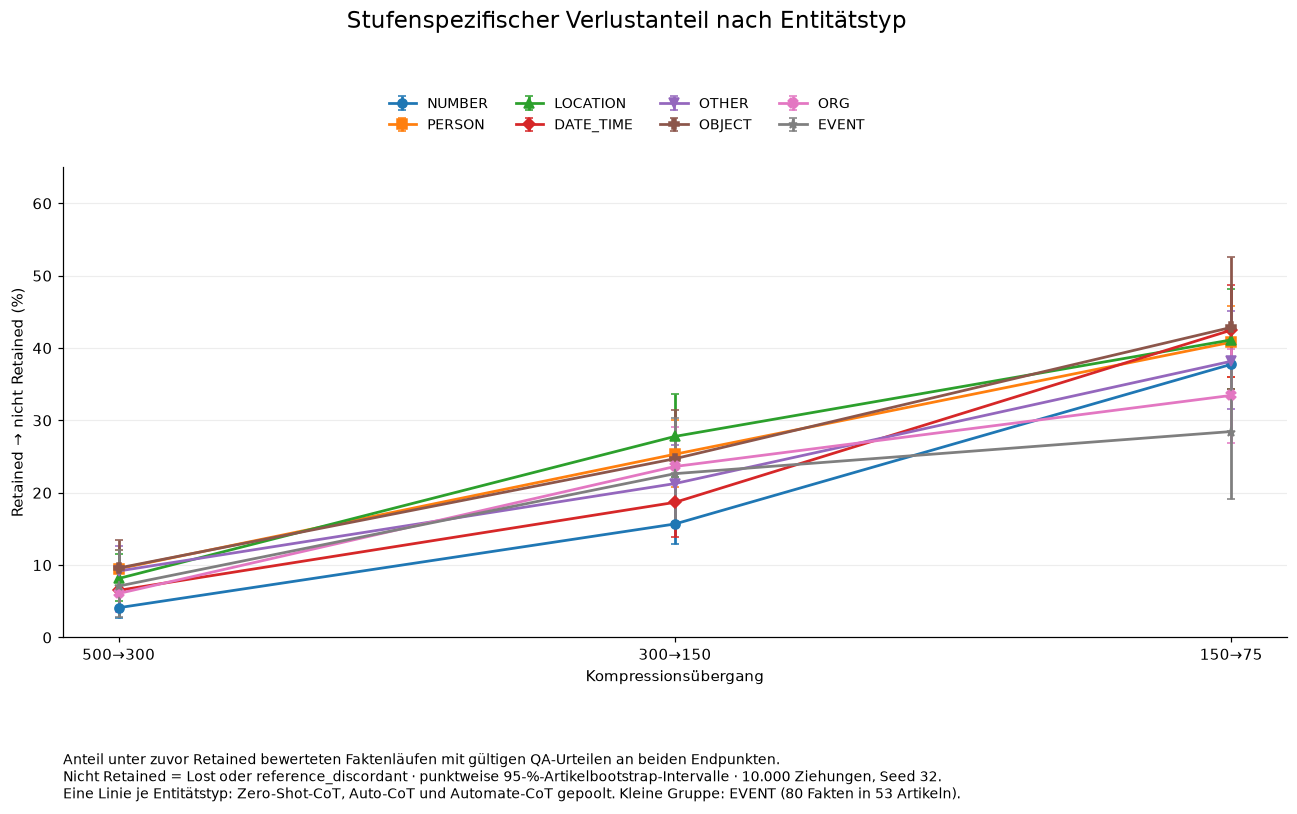

In [11]:
PLOT_GROUP = "Drei generative Verfahren gepoolt"
TYPE_COLORS = dict(zip(TYPES,plt.get_cmap("tab10").colors[:len(TYPES)]))
TYPE_MARKERS = dict(zip(TYPES,["o","s","^","D","v","P","X","*"]))
transition_order = ["500→300","300→150","150→75"]
xx = np.arange(3)
fig,ax=plt.subplots(figsize=(12.5,7.5))
for typ in TYPES:
    sub=loss_by_type[(loss_by_type.entity_type.eq(typ))&
                     (loss_by_type.method_group.eq(PLOT_GROUP))].set_index("transition").loc[transition_order]
    y=sub.loss_percent.to_numpy()
    yerr=np.vstack([y-sub.loss_ci_low_percent.to_numpy(),sub.loss_ci_high_percent.to_numpy()-y])
    ax.errorbar(xx,y,yerr=yerr,color=TYPE_COLORS[typ],marker=TYPE_MARKERS[typ],
                linestyle="-",linewidth=1.8,markersize=6,capsize=2.5,label=typ)
ax.set(xticks=xx,xticklabels=transition_order,ylim=(0,65),yticks=np.arange(0,66,10),
       xlabel="Kompressionsübergang",ylabel="Retained → nicht Retained (%)")
ax.grid(axis="y",alpha=.22);ax.set_axisbelow(True)
fig.suptitle("Stufenspezifischer Verlustanteil nach Entitätstyp",fontsize=15,y=.98)
fig.legend(loc="upper center",bbox_to_anchor=(.5,.89),ncol=4,frameon=False,fontsize=9)
fig.subplots_adjust(top=.79,bottom=.22,left=.09,right=.98)
fig.text(.09,.025,"Anteil unter zuvor Retained bewerteten Faktenläufen mit gültigen QA-Urteilen an beiden Endpunkten.\n"
         "Nicht Retained = Lost oder reference_discordant · punktweise 95-%-Artikelbootstrap-Intervalle · 10.000 Ziehungen, Seed 32.\n"
         "Eine Linie je Entitätstyp: Zero-Shot-CoT, Auto-CoT und Automate-CoT gepoolt. Kleine Gruppe: EVENT (80 Fakten in 53 Artikeln).",fontsize=9)
savefig(fig,"03_verlustrisiko_nach_typ_und_stufe")

## Anhang A: Rückkehrmuster anhand konkreter Texte und QA-Belege

Die folgenden **fünf gezielt ausgewählten Fälle** illustrieren Labelwechsel; sie sind
keine Zufallsstichprobe und keine quantitative Human-Validierung. Drei betreffen Lead-k,
zwei generative Verfahren. Angezeigt werden Originalfakt, Referenz, alle vier
QA-Antworten, Belege und die vollständigen Zusammenfassungen zum Aufklappen.

Bei Lead-k wird zusätzlich für alle Artikel geprüft, ob die kürzeren Texte tatsächlich
Präfixe der längeren sind. Ein späterer Textbeleg, der bereits im früheren Text vorkommt,
spricht gegen eine wörtliche Wiederaufnahme dieser Passage als Erklärung des Labelwechsels.
Das prüft Textinklusion, nicht die semantische Korrektheit jeder Antwort.

In [12]:
lead = summaries[summaries.method.eq("lead_k")].set_index("article_id")
prefix_rows = []
for a in IDS:
    for before,after in zip(STAGES[:-1],STAGES[1:]):
        prefix_rows.append({"article_id":a,"from_stage":before,"to_stage":after,
                            "nested_prefix":lead.loc[a,f"summary_{before}"].startswith(lead.loc[a,f"summary_{after}"])})
prefix_audit = pd.DataFrame(prefix_rows)
export(prefix_audit,"lead_k_praefixpruefung")
display(prefix_audit.groupby(["from_stage","to_stage"]).nested_prefix.agg(["sum","count"]))

CASES = [
    ("lead_k",15,"15_F09","Bei 500 nennt die Antwort nur Real Madrid, bei 300 eine Liste einschließlich Bayern Munich. Die Belegpassage nennt die Clubs bereits bei 500. Die Texte sind verschachtelt; der Wechsel betrifft die QA-Antwortauswahl und deren Referenzabgleich."),
    ("lead_k",7,"7_F02","Bei 300 antwortet QA mit Gongapur, bei 150 mit dem mehrstöckigen Wohngebäude. Der kürzere Text ist ein Präfix des längeren; die Antwortauswahl wechselt zwischen unterschiedlichen Ortsangaben."),
    ("lead_k",14,"14_F08","Bei 150 lautet die Antwort NOT_FOUND, bei 75 cricket green. Die Belegpassage der 75-Wörter-Antwort ist bereits im 150-Wörter-Text vorhanden. Dieser Rückwechsel belegt daher keine neu eingefügte Information."),
    ("few_shot_cot",2,"2_F09","Bei 300 lautet die Antwort Jabhat al-Nusra, bei 150 Anti-regime groups (now Jabhat al-Nusra). Die jeweilige Belegpassage enthält beide Beschreibungen. Die Veränderung des Referenzabgleichs zeigt die Abhängigkeit vom Antwortwortlaut."),
    ("auto_cot",17,"17_F14","Bei 150 antwortet QA mit 30 %, bei 75 mit 70 %. Die Passage zu Djokovics 70 % und Isners 30 % gewonnenen Punkten ist auf beiden Stufen vorhanden; die Referenzfrage betrifft dagegen Isners verlorene Punkte. Bereits bei 300 wird die Antwort 30 percent trotz abweichender Zahl als Retained bewertet. Diese Fälle zeigen Grenzen der Antwortauswahl und des lexikalischen Referenzabgleichs; sie belegen keine Wiedergewinnung von Information.")
]
evidence_parts=[]
for method,a,f,note in CASES:
    sub = qa[qa.method.eq(method)&qa.article_id.eq(a)&qa.canonical_fact_id.eq(f)].set_index("stage_target_words").loc[STAGES].reset_index().copy()
    assert len(sub)==4 and classify(sub.label.tolist())[3]
    sub["case_note"] = note
    sub["lead_nested_prefix_all"] = bool(prefix_audit[prefix_audit.article_id.eq(a)].nested_prefix.all()) if method=="lead_k" else "not_applicable"
    support_previous=[]
    for i,row in sub.iterrows():
        support = " ".join(row.support.split()).casefold()
        support_previous.append(bool(support and support in " ".join(sub.iloc[i-1].summary.split()).casefold()) if i else None)
    sub["support_in_previous_stage_text"] = support_previous
    evidence_parts.append(sub)
    display(Markdown(f"### {LABELS[method]} · Artikel {a} · Fakt {f}\n\n"
                     f"**Ausgangsfakt:** {sub.iloc[0].fact}\n\n**Frage:** {sub.iloc[0].question}\n\n"
                     f"**Referenzantwort:** {sub.iloc[0].reference_answer}\n\n**Beobachtung:** {note}"))
    with pd.option_context("display.max_colwidth",None):
        display(sub[["stage_target_words","label","answer","support","support_in_previous_stage_text"]])
    blocks = [f'<details><summary>{int(row.stage_target_words)} Wörter: vollständige Zusammenfassung</summary><pre style="white-space:pre-wrap">{html.escape(row.summary)}</pre></details>' for _,row in sub.iterrows()]
    display(HTML("\n".join(blocks)))
evidence = pd.concat(evidence_parts,ignore_index=True)
export(evidence[KEY+["entity_type","fact","question","reference_answer","source_evidence","label","answer","support","summary","grounded","answer_origin","case_note","lead_nested_prefix_all","support_in_previous_stage_text"]],"rueckkehr_beispiele_mit_texten_und_belegen")
assert evidence[(evidence.method=="lead_k")&(evidence.canonical_fact_id=="14_F08")&(evidence.stage_target_words==75)].support_in_previous_stage_text.all()

,,sum,count
from_stage,to_stage,,
150,75,100,100
300,150,100,100
500,300,100,100


### Lead-k · Artikel 15 · Fakt 15_F09

**Ausgangsfakt:** Bayern Munich has shown interest in Sterling.

**Frage:** Which club among others has attracted interest in Sterling?

**Referenzantwort:** Bayern Munich

**Beobachtung:** Bei 500 nennt die Antwort nur Real Madrid, bei 300 eine Liste einschließlich Bayern Munich. Die Belegpassage nennt die Clubs bereits bei 500. Die Texte sind verschachtelt; der Wechsel betrifft die QA-Antwortauswahl und deren Referenzabgleich.

,stage_target_words,label,answer,support,support_in_previous_stage_text
0,500,reference_discordant,Real Madrid,"Sterling has attracted interest from clubs including Real Madrid, Bayern Munich, Manchester City and Arsenal .",None
1,300,retained,"Real Madrid, Bayern Munich, Manchester City and Arsenal","Sterling has attracted interest from clubs including Real Madrid, Bayern Munich, Manchester City and Arsenal",True
2,150,reference_discordant,Arsenal,linked to Arsenal,True
3,75,lost,NOT_FOUND,,False


### Lead-k · Artikel 7 · Fakt 7_F02

**Ausgangsfakt:** Pemba Tamang was rescued from a multistory residential building in Kathmandu.

**Frage:** Where was Pemba Tamang rescued from?

**Referenzantwort:** rubble of a multistory residential building in one of Kathmandu's hard-hit neighborhoods

**Beobachtung:** Bei 300 antwortet QA mit Gongapur, bei 150 mit dem mehrstöckigen Wohngebäude. Der kürzere Text ist ein Präfix des längeren; die Antwortauswahl wechselt zwischen unterschiedlichen Ortsangaben.

,stage_target_words,label,answer,support,support_in_previous_stage_text
0,500,retained,the rubble of a multistory residential building,rescuers pulled an 15-year-old from the rubble of a multistory residential building in one of Kathmandu's hard-hit neighborhoods.,None
1,300,reference_discordant,the Gongapur area,rushed from the Gongapur area,True
2,150,retained,the rubble of a multistory residential building,rescuers pulled an 15-year-old from the rubble of a multistory residential building in one of Kathmandu's hard-hit neighborhoods,True
3,75,retained,the rubble of a multistory residential building,rescuers pulled an 15-year-old from the rubble of a multistory residential building,True


...

,stage_target_words,label,answer,support,support_in_previous_stage_text
0,500,retained,cricket green,"The current owner installed a cricket green, pictured, on the estate",None
1,300,retained,cricket green,"The current owner installed a cricket green, pictured, on the estate",True
2,150,lost,NOT_FOUND,,False
3,75,retained,cricket green,even its own cricket green,True


### Few-Shot-CoT · Artikel 2 · Fakt 2_F09

**Ausgangsfakt:** Anti-regime groups hold the inside of Yarmouk.

**Frage:** Who holds the inside of Yarmouk?

**Referenzantwort:** anti-regime groups

**Beobachtung:** Bei 300 lautet die Antwort Jabhat al-Nusra, bei 150 Anti-regime groups (now Jabhat al-Nusra). Die jeweilige Belegpassage enthält beide Beschreibungen. Die Veränderung des Referenzabgleichs zeigt die Abhängigkeit vom Antwortwortlaut.

,stage_target_words,label,answer,support,support_in_previous_stage_text
0,500,retained,anti-regime groups (now Jabhat al-Nusra),"while anti-regime groups (now Jabhat al-Nusra, after ISIS withdrew) control the interior",None
1,300,reference_discordant,Jabhat al-Nusra,"anti-regime groups (now Jabhat al-Nusra, after ISIS withdrew) control the interior",True
2,150,retained,Anti-regime groups (now Jabhat al-Nusra),"Anti-regime groups (now Jabhat al-Nusra, after ISIS withdrew) control the interior",True
3,75,retained,Anti-regime groups (Jabhat al-Nusra now),Anti-regime groups (Jabhat al-Nusra now) control the interior,False


### Auto-CoT · Artikel 17 · Fakt 17_F14

**Ausgangsfakt:** John Isner lost 70 percent of his second-serve points.

**Frage:** What percentage of second-serve points did John Isner lose?

**Referenzantwort:** 70 percent

**Beobachtung:** Bei 150 antwortet QA mit 30 %, bei 75 mit 70 %. Die Passage zu Djokovics 70 % und Isners 30 % gewonnenen Punkten ist auf beiden Stufen vorhanden; die Referenzfrage betrifft dagegen Isners verlorene Punkte. Bereits bei 300 wird die Antwort 30 percent trotz abweichender Zahl als Retained bewertet. Diese Fälle zeigen Grenzen der Antwortauswahl und des lexikalischen Referenzabgleichs; sie belegen keine Wiedergewinnung von Information.

,stage_target_words,label,answer,support,support_in_previous_stage_text
0,500,retained,70 percent,winning just 30 percent of those points,None
1,300,retained,30 percent,Isner’s 30 percent,False
2,150,reference_discordant,30%,Isner’s 30%,False
3,75,retained,70%,won 70% of second-serve points (vs. Isner’s 30%),True


## Anhang B: Generierungsfehler und gemeinsame Sensitivität

Zwei leere Zero-Shot-CoT-Ausgaben wurden in der Quellauswertung mit insgesamt 40
regelbasierten NOT_FOUND-Positionen bewertet. Eine Kette wurde anschließend mit leerer
Eingabe fortgesetzt. Das sind Generierungsfehler, keine technischen QA-Fehlwerte.
Die Hauptauswertung enthält sie; diese Sensitivität entfernt die beiden betroffenen
Artikel bei **allen** Verfahren und erhält eine gemeinsame Artikelbasis.

In [13]:
sensitivity_first=[]; sensitivity_types=[]
for method in METHODS:
    sub = paths[paths.method.eq(method)&~paths.article_id.isin(failed_ids)]
    for cat in FIRSTS:
        n=int(sub.first_category.eq(cat).sum())
        sensitivity_first.append({"method":method,"category":cat,"n_numerator":n,"n_denominator":len(sub),"estimate":n/len(sub),"n_articles":sub.article_id.nunique()})
for (typ,method,stage),sub in qa[~qa.article_id.isin(failed_ids)].groupby(["entity_type","method","stage_target_words"]):
    n=int(sub.label.eq(R).sum()); v=int(sub.analysis_eligible.sum())
    sensitivity_types.append({"entity_type":typ,"method":method,"stage_target_words":stage,"n_numerator":n,"n_denominator":v,"estimate":n/v if v else np.nan,"n_articles":sub.article_id.nunique()})
sensitivity_first = pd.DataFrame(sensitivity_first); sensitivity_types = pd.DataFrame(sensitivity_types)
export(sensitivity_first,"sensitivitaet_ohne_generierungsfehler_erste_stufe")
export(sensitivity_types,"sensitivitaet_ohne_generierungsfehler_entitaetstypen")
shift = sensitivity_first.merge(firsts[["method","category","estimate"]],on=["method","category"],suffixes=("_sensitivity","_main"))
max_shift = 100*(shift.estimate_sensitivity-shift.estimate_main).abs().max()
display(Markdown(f"**Gemeinsame Sensitivität:** {100-len(failed_ids)} Artikel, {(100-len(failed_ids))*20} Laufbahnen je Verfahren. "
                 f"Größte absolute Änderung einer Kategorie der ersten Stufe: {fmt(max_shift,2)} Prozentpunkte. "
                 "Die Sensitivität ist deskriptiv; sie beseitigt keine allgemeinen QA-Messfehler."))

**Gemeinsame Sensitivität:** 98 Artikel, 1960 Laufbahnen je Verfahren. Größte absolute Änderung einer Kategorie der ersten Stufe: 0,72 Prozentpunkte. Die Sensitivität ist deskriptiv; sie beseitigt keine allgemeinen QA-Messfehler.

## Anhang C: vollständige Tabellen und kurzer Ergebnistext für Kapitel 4.4

Die Übergangsdatei enthält alle Zähler, Paar- und bedingten Nenner sowie punktweise
Artikelbootstrap-Intervalle. Die 4×4-Datei hält Lost, Referenzabweichungen und technische
Fehlwerte getrennt, einschließlich aller Nullzellen. Die Typendatei enthält für jede
Methode und Stufe Retained-Zähler, gültige Nenner, Fehlwerte sowie Fakten- und Artikelzahlen.
Der folgende Text wird aus den berechneten Tabellen erzeugt; mögliche Ursachen und
Qualitätsfolgen werden erst in Kapitel 5 vertieft.

In [14]:
flookup = firsts.set_index(["method","category"])
persist_lookup = persistence.set_index(["method","outcome"])
lines = ["# 4.4 Verlustmuster", 
    "Die explorative Auswertung zu F4 verfolgte 2.000 kanonische Ausgangsfakten aus 100 Testartikeln (20 je Artikel) unter sechs Verfahren über 500, 300, 150 und 75 Zielwörter. Die Analyseeinheit war die Faktenlaufbahn, identifiziert durch Artikel-ID, kanonische Fakten-ID und Verfahren; insgesamt lagen 12.000 Laufbahnen mit 48.000 QA-Positionen vor. Verwendet wurde ausschließlich aktuell_20260930, einschließlich der ersetzten Plain- und Few-Shot-CoT-Ketten.",
    f"Nicht Retained fasst die tatsächlichen Quelllabels Lost und reference_discordant zusammen. Ein separates Unsupported-Label liegt nicht vor; Referenzabweichungen sind kein Halluzinationsnachweis. Die {int(qa.technical_missing.sum())} technischen QA-Fehlwerte wurden nicht als Verlust gewertet. Ein Fehlwert vor einem ersten beobachteten Nicht-Retained-Label oder in einer ansonsten vollständig Retained-bewerteten Laufbahn verhindert die eindeutige Bestimmung der ersten Stufe. Fehlwerte nach einer eindeutig bestimmten ersten Stufe können die Persistenz offenlassen. Die erste Stufe 500 bezeichnet bereits eine Zusammenfassung.",
    "## 4.4.1 Verlust entlang der Kompressionskette",
    "Abbildung 4.4a zeigt je Verfahren die erste eindeutig bestimmbare Nicht-Retained-Stufe und die bis 75 durchgehend Retained-bewerteten Laufbahnen. Der Nenner beträgt stets 2.000 Ausgangsfakten je Verfahren; die unbestimmbaren Laufbahnen bleiben als eigene Kategorie erhalten."]
for m in METHODS:
    dist = firsts[firsts.method.eq(m)].set_index("category")
    vals = "; ".join(f"{t} Wörter: {int(dist.loc[str(t),'n_numerator'])}/2.000 ({fmt(100*dist.loc[str(t),'estimate'])} %)" for t in STAGES)
    always = dist.loc["always_retained"]; unknown=dist.loc["undetermined"]
    lines.append(f"{LABELS[m]}: erstmals nicht Retained bei {vals}. Durchgehend Retained blieben {int(always.n_numerator)}/2.000 ({fmt(100*always.estimate)} %); {int(unknown.n_numerator)}/2.000 ({fmt(100*unknown.estimate)} %) waren bezüglich der ersten Stufe nicht eindeutig bestimmbar.")
lines.append("Für die Persistenz wurden nur Laufbahnen mit eindeutiger erster Nicht-Retained-Stufe vor 75 betrachtet. Laufbahnen mit erstem Label bei 75 haben keine beobachtete Folgestufe und zählen nicht als Nachweis anhaltender Nicht-Retention.")
for m in METHODS:
    p=persist_lookup.loc[(m,"all_later_non_retained")]; ret=persist_lookup.loc[(m,"observed_return")]; u=persist_lookup.loc[(m,"persistence_undetermined")]
    lines.append(f"Bei {LABELS[m]} blieben {int(p.n_numerator)}/{int(p.n_denominator)} ({fmt(100*p.estimate)} %) der betreffenden Laufbahnen danach auf allen Stufen nicht Retained. Bei {int(ret.n_numerator)}/{int(ret.n_denominator)} ({fmt(100*ret.estimate)} %) erschien später mindestens ein Retained-Label; bei {int(u.n_numerator)}/{int(u.n_denominator)} blieb die Persistenz wegen späterer technischer Fehlwerte offen.")
# Descriptive selections show both denominators without treating selection as a test.
for m in ["lead_k","auto_cot"]:
    row=transitions[transitions.method.eq(m)].sort_values("r_to_n_pair_estimate",ascending=False).iloc[0]
    lines.append(f"Der größte beobachtete Paaranteil Retained → nicht Retained bei {LABELS[m]} trat bei {row.transition} auf: {int(row.r_to_n_pair_n_numerator)}/{int(row.n_valid_pairs)} ({fmt(100*row.r_to_n_pair_estimate)} %) gültige Paare. Bezogen auf die gültigen Paare mit Retained-Ausgangslabel waren es {int(row.r_to_n_conditional_n_numerator)}/{int(row.r_to_n_conditional_n_denominator)} ({fmt(100*row.r_to_n_conditional_estimate)} %). Diese Auswahl des größten Anteils ist deskriptiv.")
lead_return = transitions[transitions.method.eq("lead_k")]
lines.append("Bei Lead-k wurden folgende Rückwechsel nicht Retained → Retained beobachtet: "+"; ".join(f"{r.transition}: {int(r.n_to_r_pair_n_numerator)}/{int(r.n_valid_pairs)} gültige Paare ({fmt(100*r.n_to_r_pair_estimate)} %), bedingt {int(r.n_to_r_conditional_n_numerator)}/{int(r.n_to_r_conditional_n_denominator)} ({fmt(100*r.n_to_r_conditional_estimate)} %)" for _,r in lead_return.iterrows())+".")
lines.append(f"Bei Lead-k waren {int(prefix_audit.nested_prefix.sum())}/{len(prefix_audit)} geprüften Stufenpaaren verschachtelte Präfixe. Die exemplarische Textprüfung zeigte bei Artikel 14, Fakt 14_F08, trotz NOT_FOUND bei 150 und Retained bei 75 denselben späteren Beleg bereits im längeren Text. Bei Artikel 15, Fakt 15_F09, änderte sich die Antwortauswahl bei einer bereits vorhandenen Club-Liste. Rückwechsel belegen somit zunächst Änderungen automatischer QA-Urteile, keine tatsächliche Wiedergewinnung verschwundener Information. Fünf gezielt ausgewählte Beispiele samt vollständigen Texten stehen im Notebook-Anhang; sie erlauben keine Schätzung der QA-Fehlerrate.")
lines += ["## 4.4.2 Unterschiede nach Entitätstyp",
    "Abbildung 4.4b zeigt Retained / gültige QA-Urteile je Entitätstyp, Verfahren und Zielstufe. Dieser Anteil ist faktengewichtet, im Unterschied zu den gleichgewichteten Artikelmitteln in 4.2. Die punktweisen 95-%-Perzentilintervalle verwenden 10.000 Artikelbootstrap-Ziehungen mit Seed 32; alle Fakten, Verfahren und Stufen eines Artikels bleiben gemeinsam. Die Intervalle berücksichtigen die Artikelheterogenität, keine Unsicherheit der automatischen Bewertung. Es gibt keine vorab festgelegte Typenrangfolge; sämtliche Vergleiche bleiben explorativ."]
lines.append("Die Fallzahlen der acht Entitätstypen betrugen: "+"; ".join(f"{r.entity_type}: {r.n_facts} Ausgangsfakten in {r.n_articles} Artikeln" for _,r in type_counts.iterrows())+". Kleine Gruppen werden bei weniger als 100 Fakten oder 30 Artikeln markiert; damit ist EVENT (80 Fakten, 53 Artikel) als relativ kleine Gruppe gekennzeichnet. Die zugrunde liegenden Fakten werden einmal gezählt, nicht erneut pro Verfahren oder Stufe.")
leaders=[]
for transition in ["500→300","300→150","150→75"]:
    top=selected_loss[selected_loss.transition.eq(transition)].sort_values("loss_percent",ascending=False).iloc[0]
    leaders.append(f"{transition}: {top.entity_type} {int(top.n_retained_to_nonretained)}/{int(top.n_retained_at_start)} = {fmt(top.loss_percent)} % (95-%-KI [{fmt(top.loss_ci_low_percent)}; {fmt(top.loss_ci_high_percent)}])")
net_leaders=[]
for transition in ["500→300","300→150","150→75"]:
    top=selected_loss[selected_loss.transition.eq(transition)].sort_values("net_loss_pp",ascending=False).iloc[0]
    net_leaders.append(f"{transition}: {top.entity_type} ({fmt(top.net_loss_pp)} Prozentpunkte netto)")
lines.append("Im gepoolten Übergangsvergleich der fünf generativen Verfahren war der bedingte Verlustanteil — unter gültigen Ausgangsfällen mit Retained-Label — bei folgenden Typen am höchsten: "+"; ".join(leaders)+". Nach Nettoänderung, bei der Rückwechsel abgezogen werden, lauten die höchsten Werte: "+"; ".join(net_leaders)+". Die Rangfolgen unterscheiden sich, weil einige Faktenläufe wieder zu Retained wechseln. Die Intervalle überlappen; die höchsten Punktschätzungen belegen keine eindeutigen Typenunterschiede. Details und Nenner je Typ stehen in der ergänzenden Übergangstabelle.")
lines.append("Abbildung 4.4c stellt das stufenspezifische Risiko als Retained→nicht-Retained-Anteil unter den zuvor Retained bewerteten Fällen dar. Zero-Shot-CoT, Auto-CoT und Automate-CoT sind für jede Linie zusammengefasst; alle acht Entitätstypen werden gemeinsam gezeigt. So lässt sich erkennen, bei welchen Typen die Verlustanteile an den späteren Übergängen ansteigen. Die Intervalle sind artikelbasiert; überlappende Intervalle und die explorative Auswahl erlauben keine gesicherte Rangfolge.")
# Describe observed values for selected actual types; no aggregate ranking or significance assertion.
for typ in ["NUMBER","PERSON","LOCATION","EVENT"]:
    sub=type_retention[type_retention.entity_type.eq(typ)&type_retention.stage_target_words.eq(75)]
    vals="; ".join(f"{LABELS[r.method]}: {int(r.n_numerator)}/{int(r.n_denominator)} ({fmt(100*r.estimate)} %)" for _,r in sub.iterrows())
    lines.append(f"Bei 75 Wörtern ergaben sich für {typ} folgende Werte unter gültigen QA-Urteilen: {vals}. Die methodenspezifischen Intervalle und alle übrigen Typen/Stufen stehen in Abbildung und Anhang.")
# Direct, transparent within-method contrast, without treating the facts as independent.
comp = type_retention[type_retention.stage_target_words.eq(75)].pivot(index="method",columns="entity_type",values="estimate").reindex(METHODS)
number_higher = int((comp.NUMBER>comp.PERSON).sum())
lines += ["## Kurzer Abschluss",
    f"Die Laufbahnen unterscheiden frühe Nicht-Retained-Bewertungen bei 500 von späteren Bewertungen und von vollständig erhaltenen Laufbahnen. Rückwechsel treten auf und müssen als QA-Labelwechsel gelesen werden. In {number_higher}/6 Verfahren lag bei 75 Wörtern der beobachtete faktengewichtete Anteil für NUMBER über PERSON. Das ist ein explorativer Befund ohne bestätigte Typenrangfolge; insbesondere EVENT beruht auf einer kleineren Faktenbasis. Ursachen und die Bedeutung für die Zusammenfassungsqualität werden in Kapitel 5 diskutiert.",
    f"Die Hauptauswertung enthält 40 regelbasierte NOT_FOUND-Positionen aus zwei leeren Zero-Shot-CoT-Ausgaben. Die gemeinsame Sensitivität ohne die beiden betroffenen Artikel umfasst 98 Artikel und 1.960 Faktenlaufbahnen je Verfahren; die größte absolute Änderung einer Kategorie der ersten Stufe beträgt {fmt(max_shift,2)} Prozentpunkte. Die Sensitivität beseitigt keine allgemeinen QA-Messfehler.",
    "**Abbildung 4.4a:** Erste Nicht-Retained-Bewertung je Verfahren, einschließlich durchgehend Retained und nicht eindeutig bestimmbarer Laufbahnen; n = 2.000 je Verfahren. Nicht Retained = Lost oder reference_discordant; technische QA-Fehlwerte erhalten kein Verlustlabel.",
    "**Abbildung 4.4b:** Faktengewichtete QA-Retention nach Entitätstyp über die vier Zielstufen; gleiche Skalen, Fakten- und Artikelzahlen je Panel, punktweise 95-%-Artikelbootstrap-Intervalle. EVENT ist nach der angegebenen Darstellungsschwelle eine kleine Gruppe.",
    "**Abbildung 4.4c:** Anteil der zuvor Retained bewerteten Faktenläufe, die je Übergang zu Lost oder reference_discordant wechseln; Zero-Shot-CoT, Auto-CoT und Automate-CoT gepoolt zu einer Linie je Typ. Alle acht Entitätstypen in einem gemeinsamen Diagramm. Nenner und punktweise 95-%-Artikelbootstrap-Intervalle stehen in der Übergangstabelle."]
chapter = "\n\n".join(lines)
(OUT/"Kapitel_4_4_Verlustmuster.md").write_text(chapter,encoding="utf-8")
display(Markdown(chapter))

# 4.4 Verlustmuster

Die explorative Auswertung zu F4 verfolgte 2.000 kanonische Ausgangsfakten aus 100 Testartikeln (20 je Artikel) unter sechs Verfahren über 500, 300, 150 und 75 Zielwörter. Die Analyseeinheit war die Faktenlaufbahn, identifiziert durch Artikel-ID, kanonische Fakten-ID und Verfahren; insgesamt lagen 12.000 Laufbahnen mit 48.000 QA-Positionen vor. Verwendet wurde ausschließlich aktuell_20260930, einschließlich der ersetzten Plain- und Few-Shot-CoT-Ketten.

Nicht Retained fasst die tatsächlichen Quelllabels Lost und reference_discordant zusammen. Ein separates Unsupported-Label liegt nicht vor; Referenzabweichungen sind kein Halluzinationsnachweis. Die 196 technischen QA-Fehlwerte wurden nicht als Verlust gewertet. Ein Fehlwert vor einem ersten beobachteten Nicht-Retained-Label oder in einer ansonsten vollständig Retained-bewerteten Laufbahn verhindert die eindeutige Bestimmung der ersten Stufe. Fehlwerte nach einer eindeutig bestimmten ersten Stufe können die Persistenz offenlassen. Die erste Stufe 500 bezeichnet bereits eine Zusammenfassung.

## 4.4.1 Verlust entlang der Kompressionskette

Abbildung 4.4a zeigt je Verfahren die erste eindeutig bestimmbare Nicht-Retained-Stufe und die bis 75 durchgehend Retained-bewerteten Laufbahnen. Der Nenner beträgt stets 2.000 Ausgangsfakten je Verfahren; die unbestimmbaren Laufbahnen bleiben als eigene Kategorie erhalten.

Lead-k: erstmals nicht Retained bei 500 Wörter: 487/2.000 (24,3 %); 300 Wörter: 532/2.000 (26,6 %); 150 Wörter: 388/2.000 (19,4 %); 75 Wörter: 254/2.000 (12,7 %). Durchgehend Retained blieben 332/2.000 (16,6 %); 7/2.000 (0,4 %) waren bezüglich der ersten Stufe nicht eindeutig bestimmbar.

Plain: erstmals nicht Retained bei 500 Wörter: 898/2.000 (44,9 %); 300 Wörter: 122/2.000 (6,1 %); 150 Wörter: 101/2.000 (5,1 %); 75 Wörter: 229/2.000 (11,5 %). Durchgehend Retained blieben 634/2.000 (31,7 %); 16/2.000 (0,8 %) waren bezüglich der ersten Stufe nicht eindeutig bestimmbar.

Zero-Shot-CoT: erstmals nicht Retained bei 500 Wörter: 560/2.000 (28,0 %); 300 Wörter: 103/2.000 (5,1 %); 150 Wörter: 295/2.000 (14,8 %); 75 Wörter: 489/2.000 (24,4 %). Durchgehend Retained blieben 544/2.000 (27,2 %); 9/2.000 (0,4 %) waren bezüglich der ersten Stufe nicht eindeutig bestimmbar.

Few-Shot-CoT: erstmals nicht Retained bei 500 Wörter: 710/2.000 (35,5 %); 300 Wörter: 82/2.000 (4,1 %); 150 Wörter: 222/2.000 (11,1 %); 75 Wörter: 323/2.000 (16,2 %). Durchgehend Retained blieben 638/2.000 (31,9 %); 25/2.000 (1,2 %) waren bezüglich der ersten Stufe nicht eindeutig bestimmbar.

Auto-CoT: erstmals nicht Retained bei 500 Wörter: 569/2.000 (28,4 %); 300 Wörter: 88/2.000 (4,4 %); 150 Wörter: 228/2.000 (11,4 %); 75 Wörter: 381/2.000 (19,1 %). Durchgehend Retained blieben 717/2.000 (35,9 %); 17/2.000 (0,9 %) waren bezüglich der ersten Stufe nicht eindeutig bestimmbar.

Automate-CoT: erstmals nicht Retained bei 500 Wörter: 529/2.000 (26,5 %); 300 Wörter: 114/2.000 (5,7 %); 150 Wörter: 315/2.000 (15,8 %); 75 Wörter: 329/2.000 (16,4 %). Durchgehend Retained blieben 691/2.000 (34,5 %); 22/2.000 (1,1 %) waren bezüglich der ersten Stufe nicht eindeutig bestimmbar.

Für die Persistenz wurden nur Laufbahnen mit eindeutiger erster Nicht-Retained-Stufe vor 75 betrachtet. Laufbahnen mit erstem Label bei 75 haben keine beobachtete Folgestufe und zählen nicht als Nachweis anhaltender Nicht-Retention.

Bei Lead-k blieben 1384/1407 (98,4 %) der betreffenden Laufbahnen danach auf allen Stufen nicht Retained. Bei 21/1407 (1,5 %) erschien später mindestens ein Retained-Label; bei 2/1407 blieb die Persistenz wegen späterer technischer Fehlwerte offen.

Bei Plain blieben 1064/1121 (94,9 %) der betreffenden Laufbahnen danach auf allen Stufen nicht Retained. Bei 53/1121 (4,7 %) erschien später mindestens ein Retained-Label; bei 4/1121 blieb die Persistenz wegen späterer technischer Fehlwerte offen.

Bei Zero-Shot-CoT blieben 882/958 (92,1 %) der betreffenden Laufbahnen danach auf allen Stufen nicht Retained. Bei 72/958 (7,5 %) erschien später mindestens ein Retained-Label; bei 4/958 blieb die Persistenz wegen späterer technischer Fehlwerte offen.

Bei Few-Shot-CoT blieben 919/1014 (90,6 %) der betreffenden Laufbahnen danach auf allen Stufen nicht Retained. Bei 86/1014 (8,5 %) erschien später mindestens ein Retained-Label; bei 9/1014 blieb die Persistenz wegen späterer technischer Fehlwerte offen.

Bei Auto-CoT blieben 789/885 (89,2 %) der betreffenden Laufbahnen danach auf allen Stufen nicht Retained. Bei 92/885 (10,4 %) erschien später mindestens ein Retained-Label; bei 4/885 blieb die Persistenz wegen späterer technischer Fehlwerte offen.

Bei Automate-CoT blieben 872/958 (91,0 %) der betreffenden Laufbahnen danach auf allen Stufen nicht Retained. Bei 81/958 (8,5 %) erschien später mindestens ein Retained-Label; bei 5/958 blieb die Persistenz wegen späterer technischer Fehlwerte offen.

Der größte beobachtete Paaranteil Retained → nicht Retained bei Lead-k trat bei 500→300 auf: 532/1994 (26,7 %) gültige Paare. Bezogen auf die gültigen Paare mit Retained-Ausgangslabel waren es 532/1507 (35,3 %). Diese Auswahl des größten Anteils ist deskriptiv.

Der größte beobachtete Paaranteil Retained → nicht Retained bei Auto-CoT trat bei 150→75 auf: 408/1985 (20,6 %) gültige Paare. Bezogen auf die gültigen Paare mit Retained-Ausgangslabel waren es 408/1153 (35,4 %). Diese Auswahl des größten Anteils ist deskriptiv.

Bei Lead-k wurden folgende Rückwechsel nicht Retained → Retained beobachtet: 500→300: 10/1994 gültige Paare (0,5 %), bedingt 10/487 (2,1 %); 300→150: 9/1994 gültige Paare (0,5 %), bedingt 9/1009 (0,9 %); 150→75: 4/1996 gültige Paare (0,2 %), bedingt 4/1393 (0,3 %).

Bei Lead-k waren 300/300 geprüften Stufenpaaren verschachtelte Präfixe. Die exemplarische Textprüfung zeigte bei Artikel 14, Fakt 14_F08, trotz NOT_FOUND bei 150 und Retained bei 75 denselben späteren Beleg bereits im längeren Text. Bei Artikel 15, Fakt 15_F09, änderte sich die Antwortauswahl bei einer bereits vorhandenen Club-Liste. Rückwechsel belegen somit zunächst Änderungen automatischer QA-Urteile, keine tatsächliche Wiedergewinnung verschwundener Information. Fünf gezielt ausgewählte Beispiele samt vollständigen Texten stehen im Notebook-Anhang; sie erlauben keine Schätzung der QA-Fehlerrate.

## 4.4.2 Unterschiede nach Entitätstyp

Abbildung 4.4b zeigt Retained / gültige QA-Urteile je Entitätstyp, Verfahren und Zielstufe. Dieser Anteil ist faktengewichtet, im Unterschied zu den gleichgewichteten Artikelmitteln in 4.2. Die punktweisen 95-%-Perzentilintervalle verwenden 10.000 Artikelbootstrap-Ziehungen mit Seed 32; alle Fakten, Verfahren und Stufen eines Artikels bleiben gemeinsam. Die Intervalle berücksichtigen die Artikelheterogenität, keine Unsicherheit der automatischen Bewertung. Es gibt keine vorab festgelegte Typenrangfolge; sämtliche Vergleiche bleiben explorativ.

Die Fallzahlen der acht Entitätstypen betrugen: NUMBER: 526 Ausgangsfakten in 96 Artikeln; PERSON: 420 Ausgangsfakten in 97 Artikeln; LOCATION: 255 Ausgangsfakten in 93 Artikeln; DATE_TIME: 216 Ausgangsfakten in 90 Artikeln; OTHER: 181 Ausgangsfakten in 74 Artikeln; OBJECT: 168 Ausgangsfakten in 67 Artikeln; ORG: 154 Ausgangsfakten in 77 Artikeln; EVENT: 80 Ausgangsfakten in 53 Artikeln. Kleine Gruppen werden bei weniger als 100 Fakten oder 30 Artikeln markiert; damit ist EVENT (80 Fakten, 53 Artikel) als relativ kleine Gruppe gekennzeichnet. Die zugrunde liegenden Fakten werden einmal gezählt, nicht erneut pro Verfahren oder Stufe.

Im gepoolten Übergangsvergleich der fünf generativen Verfahren war der bedingte Verlustanteil — unter gültigen Ausgangsfällen mit Retained-Label — bei folgenden Typen am höchsten: 500→300: OBJECT 36/375 = 9,6 % (95-%-KI [6,4; 13,5]); 300→150: LOCATION 132/475 = 27,8 % (95-%-KI [22,2; 33,7]); 150→75: OBJECT 117/273 = 42,9 % (95-%-KI [34,3; 52,6]). Nach Nettoänderung, bei der Rückwechsel abgezogen werden, lauten die höchsten Werte: 500→300: OBJECT (6,6 Prozentpunkte netto); 300→150: ORG (17,0 Prozentpunkte netto); 150→75: NUMBER (23,4 Prozentpunkte netto). Die Rangfolgen unterscheiden sich, weil einige Faktenläufe wieder zu Retained wechseln. Die Intervalle überlappen; die höchsten Punktschätzungen belegen keine eindeutigen Typenunterschiede. Details und Nenner je Typ stehen in der ergänzenden Übergangstabelle.

Abbildung 4.4c stellt das stufenspezifische Risiko als Retained→nicht-Retained-Anteil unter den zuvor Retained bewerteten Fällen dar. Zero-Shot-CoT, Auto-CoT und Automate-CoT sind für jede Linie zusammengefasst; alle acht Entitätstypen werden gemeinsam gezeigt. So lässt sich erkennen, bei welchen Typen die Verlustanteile an den späteren Übergängen ansteigen. Die Intervalle sind artikelbasiert; überlappende Intervalle und die explorative Auswahl erlauben keine gesicherte Rangfolge.

Bei 75 Wörtern ergaben sich für NUMBER folgende Werte unter gültigen QA-Urteilen: Lead-k: 92/526 (17,5 %); Plain: 241/525 (45,9 %); Zero-Shot-CoT: 185/526 (35,2 %); Few-Shot-CoT: 231/526 (43,9 %); Auto-CoT: 259/526 (49,2 %); Automate-CoT: 229/526 (43,5 %). Die methodenspezifischen Intervalle und alle übrigen Typen/Stufen stehen in Abbildung und Anhang.

Bei 75 Wörtern ergaben sich für PERSON folgende Werte unter gültigen QA-Urteilen: Lead-k: 57/420 (13,6 %); Plain: 120/416 (28,8 %); Zero-Shot-CoT: 103/419 (24,6 %); Few-Shot-CoT: 114/416 (27,4 %); Auto-CoT: 130/420 (31,0 %); Automate-CoT: 130/417 (31,2 %). Die methodenspezifischen Intervalle und alle übrigen Typen/Stufen stehen in Abbildung und Anhang.

Bei 75 Wörtern ergaben sich für LOCATION folgende Werte unter gültigen QA-Urteilen: Lead-k: 57/255 (22,4 %); Plain: 57/255 (22,4 %); Zero-Shot-CoT: 58/255 (22,7 %); Few-Shot-CoT: 71/255 (27,8 %); Auto-CoT: 76/255 (29,8 %); Automate-CoT: 81/255 (31,8 %). Die methodenspezifischen Intervalle und alle übrigen Typen/Stufen stehen in Abbildung und Anhang.

Bei 75 Wörtern ergaben sich für EVENT folgende Werte unter gültigen QA-Urteilen: Lead-k: 22/80 (27,5 %); Plain: 32/79 (40,5 %); Zero-Shot-CoT: 29/80 (36,2 %); Few-Shot-CoT: 26/79 (32,9 %); Auto-CoT: 36/79 (45,6 %); Automate-CoT: 32/80 (40,0 %). Die methodenspezifischen Intervalle und alle übrigen Typen/Stufen stehen in Abbildung und Anhang.

## Kurzer Abschluss

Die Laufbahnen unterscheiden frühe Nicht-Retained-Bewertungen bei 500 von späteren Bewertungen und von vollständig erhaltenen Laufbahnen. Rückwechsel treten auf und müssen als QA-Labelwechsel gelesen werden. In 6/6 Verfahren lag bei 75 Wörtern der beobachtete faktengewichtete Anteil für NUMBER über PERSON. Das ist ein explorativer Befund ohne bestätigte Typenrangfolge; insbesondere EVENT beruht auf einer kleineren Faktenbasis. Ursachen und die Bedeutung für die Zusammenfassungsqualität werden in Kapitel 5 diskutiert.

Die Hauptauswertung enthält 40 regelbasierte NOT_FOUND-Positionen aus zwei leeren Zero-Shot-CoT-Ausgaben. Die gemeinsame Sensitivität ohne die beiden betroffenen Artikel umfasst 98 Artikel und 1.960 Faktenlaufbahnen je Verfahren; die größte absolute Änderung einer Kategorie der ersten Stufe beträgt 0,72 Prozentpunkte. Die Sensitivität beseitigt keine allgemeinen QA-Messfehler.

**Abbildung 4.4a:** Erste Nicht-Retained-Bewertung je Verfahren, einschließlich durchgehend Retained und nicht eindeutig bestimmbarer Laufbahnen; n = 2.000 je Verfahren. Nicht Retained = Lost oder reference_discordant; technische QA-Fehlwerte erhalten kein Verlustlabel.

**Abbildung 4.4b:** Faktengewichtete QA-Retention nach Entitätstyp über die vier Zielstufen; gleiche Skalen, Fakten- und Artikelzahlen je Panel, punktweise 95-%-Artikelbootstrap-Intervalle. EVENT ist nach der angegebenen Darstellungsschwelle eine kleine Gruppe.

**Abbildung 4.4c:** Anteil der zuvor Retained bewerteten Faktenläufe, die je Übergang zu Lost oder reference_discordant wechseln; Zero-Shot-CoT, Auto-CoT und Automate-CoT gepoolt zu einer Linie je Typ. Alle acht Entitätstypen in einem gemeinsamen Diagramm. Nenner und punktweise 95-%-Artikelbootstrap-Intervalle stehen in der Übergangstabelle.

In [15]:
execution_manifest = {"version":VERSION,"seed":SEED,"bootstrap_samples":B,"bootstrap_unit":"article",
    "interval":"pointwise percentile 95%","unit":"article_id × canonical_fact_id × method trajectory",
    "non_retained_labels":sorted(NON),"unsupported_label_present":False,
    "first_stage_missing_policy":"missing before first observed non-retained, or no observed non-retained with any missing => undetermined",
    "type_estimand":"pooled retained count / valid QA count; fact weighted",
    "small_group_rule":"n_unique_facts < 100 or n_articles < 30",
    "n_articles":len(IDS),"n_unique_facts":len(facts),"n_trajectories":len(paths),"n_qa":len(qa),
    "n_technical_missing":int(qa.technical_missing.sum()),"n_paths_with_missing":int(paths.n_missing.gt(0).sum()),
    "n_first_undetermined":int(paths.first_category.eq("undetermined").sum()),
    "n_synthetic_not_found":int(qa.empty_output.sum()),"generation_failure_article_ids":failed_ids,
    "source_manifest_sha256":hashlib.sha256((DATA/"source_manifest.json").read_bytes()).hexdigest(),
    "source_hashes":source_hashes,"software":{"python":platform.python_version(),**software},
    "checks":{"raw_labels_match_chapter_4_2":True,"all_expected_keys_present":True,
              "trajectory_partition_complete":True,"transition_matrices_complete":True,"type_counts_reconcile":True},
    "evidence_audit":{"selection":"five purposively selected label-return trajectories; illustrative, no error-rate estimate",
                      "cases":[{"method":m,"article_id":a,"canonical_fact_id":f} for m,a,f,_ in CASES]}}
(OUT/"execution_manifest.json").write_text(json.dumps(execution_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
files = pd.DataFrame([{"Datei":str(p.relative_to(BASE)),"Bytes":p.stat().st_size} for folder in [OUT,FIG] for p in sorted(folder.iterdir()) if p.is_file()])
display(files)
display(Markdown("**Alle Quellen-, Schlüssel-, Scorer-, Laufbahn- und Nennerprüfungen erfolgreich.** Zwei Hauptabbildungen und sämtliche Anhänge wurden neu erzeugt."))

,Datei,Bytes
0,hauptexperiment_verlust_ergebnisse/aktuell_202...,12244
1,hauptexperiment_verlust_ergebnisse/aktuell_202...,201
2,hauptexperiment_verlust_ergebnisse/aktuell_202...,2972
3,hauptexperiment_verlust_ergebnisse/aktuell_202...,2238
4,hauptexperiment_verlust_ergebnisse/aktuell_202...,6713
5,hauptexperiment_verlust_ergebnisse/aktuell_202...,2521091
6,hauptexperiment_verlust_ergebnisse/aktuell_202...,69675
7,hauptexperiment_verlust_ergebnisse/aktuell_202...,19950
8,hauptexperiment_verlust_ergebnisse/aktuell_202...,7163
9,hauptexperiment_verlust_ergebnisse/aktuell_202...,375835


**Alle Quellen-, Schlüssel-, Scorer-, Laufbahn- und Nennerprüfungen erfolgreich.** Zwei Hauptabbildungen und sämtliche Anhänge wurden neu erzeugt.